# Targeted Video Super-Resolution with a Video-Diffusion Prior: v4.2
**IE 643 · Team Pairadox** · Upload a clip, select a target on a pixel-coordinate grid. The target is **tracked**, **zoomed** and **super-resolved ×4** with a temporally consistent diffusion prior, and compared against baselines with region metrics.

### Before running (right panel)
* **Accelerator: GPU T4 ×2.** P100 will not work: Kaggle's current PyTorch is a CUDA 13 build, which dropped Pascal GPUs.
* **Internet: On.** No Hugging Face token is needed; the SD×4 upscaler is not gated.
* Run the cells **top to bottom with ▶**. Do **not** use *Save & Run All*: the last cell serves the app and never finishes.

### Time on Kaggle T4 ×2 (approximate)
| step | time | switch |
|---|---|---|
| install + write code | ~1 min | |
| weight download + GPU self-test | ~2–3 min | |
| DAVIS-2017 download (800 MB) | ~1–2 min | `TRAIN or RUN_BENCHMARK` |
| fine-tuning the temporal layers + LoRA | **12 min** (wall-clock budget) | `TRAIN`, `TRAIN_MINUTES` |
| benchmark + automatic choice of the temporal setting, 4 unseen DAVIS clips | ~12–15 min | `RUN_BENCHMARK` |
| sharpness sweep around the selected setting (v4.2) | ~12–16 min (4 clips) | `RUN_SHARP_SWEEP` |
| one interface run: 48 frames, *Balanced* | ~1–2 min | |

After training, `adapters.pt` is saved in `/kaggle/working/tvsr_ckpt/`. With `SKIP_TRAIN_IF_EXISTS = True`, a re-run reuses it. The benchmark also writes `best_config.json` there, and the interface uses those settings by default.

### What changed in v4.1 (from the first v4 run)
Measured on 4 unseen DAVIS clips (×4, realistic degradation, metrics inside the object):

| v4.0 method | LPIPS ↓ | sharpness (1 = GT) | tLPIPS ↓ | warp ×1e3 (GT 3.05) |
|---|---|---|---|---|
| Bicubic | 0.575 | 0.05 | 0.027 | 1.83 |
| Real-ESRGAN | 0.270 | 1.64 | 0.051 | 9.15 |
| SD×4 per-frame | 0.331 | 1.88 | 0.194 | 7.49 |
| **Ours v4.0** | 0.379 | **0.42** | 0.028 | 2.11 |
| Ours v4.0 without flow propagation | **0.270** | 1.28 | 0.063 | 8.62 |

* The ablation isolates the cause of the blur: **recurrent latent flow propagation**. It averaged every frame with a chain of earlier frames, re-warped bilinearly at latent (= LR) resolution. Flicker dropped, but so did detail (sharpness 0.42). Without it the method has the best detail, but it inherits the GAN estimate's flicker.
* **v4.1:** consistency is now enforced in HR pixel space with a **temporal median of three motion-aligned frames**. It removes texture that appears in only one frame but keeps edges and detail. It is applied to the initial estimate, and optionally to the output. Latent fusion became light and non-recurrent. The benchmark runs five variants on identical tubes and **picks one with a rule fixed in advance**: among variants with tLPIPS ≤ 0.04 (input-level stability), the lowest LPIPS.
* The 12-minute fine-tune gave no measurable gain (frozen ≈ trained). The report states this honestly, and the benchmark keeps the frozen-prior ablation.

### v4.1 result and what changed in v4.2
v4.1 selected **D** (stabilised initial estimate + stabilised output): LPIPS **0.253** (best of all methods), HFEN 0.771, sharpness 0.92, tLPIPS 0.034, warp 5.73. With stabilisation, training now helps (tLPIPS 0.045 → 0.034). D is still slightly soft on some clips (car 0.48, kite 0.58). Each stabilisation pass costs about 10% sharpness: 1.25 → 1.10 → 0.92.

v4.2 adds three remedies. The **sharpness sweep** (§6b) measures them with the same fixed rule:
* **Detail restore:** after stabilisation, amplify the stabilised frame's own (frame-consistent) fine detail back up to the energy of the unstabilised output. Synthetic test: sharpness 0.89 → 0.96, flicker unchanged.
* **Second short diffusion pass** (strength 0.3) starting from the stabilised result.
* **Best preset** (30 steps, strength 0.6, guidance 3 with a negative prompt) and a wider colour anchor (σ 8 instead of 3).

Post-processing variants reuse the same diffusion output, so they cost seconds.

## 1 · What was wrong with v3 (analysis)
| # | problem in v3 | effect | fix in v4 |
|---|---|---|---|
| 1 | In *Low-res (real-world)* mode every frame was shrunk to **480 px on the long side** before ×4 SR. A 1080p clip lost 75% of its pixels. | The "zoom" was an upscaled downscale, which is why the output looked unclear. | The target is cropped at the video's **native resolution**. Nothing outside the target is resampled. |
| 2 | The tube was capped at **128 LR px**: bigger targets were shrunk, then bicubic-resized back. The close-up was shown at **256 px**. | Detail was thrown away twice, and the result was shown small. | Tube up to 160 px by default (256 adjustable). The zoom is shown at full ×4 resolution, e.g. 640 px. |
| 3 | Temporal stability came from **averaging warped neighbour frames in pixel space** (Lanczos warp + mean). | High frequencies were smoothed away: low flicker, but blur. | Consistency is built **inside** the diffusion process: temporal attention, shared noise, and latent propagation in the early steps only. The last steps are free to sharpen. |
| 4 | The default never used the video-diffusion model (`SVD weight = 0`). SVD is also the wrong prior: an image-to-video generator conditioned only on the first frame, with an ×8 VAE on a 512 canvas. | Reviewer: *"bicubic outperformed…"*, *"did not establish that it recovered detail"*. | The diffusion prior is an **LR-conditioned SR model** (SD×4 Upscaler). It sees *every* frame's LR, has an ×4 VAE (latent = LR resolution), and is inflated into a video model with trained temporal layers. |
| 5 | The **whole frame** was super-resolved as background (×4 of 1080p). | Most of the runtime went to pixels nobody looks at. | Only the target tube is restored. The full video is shown with the moving zoom window. |
| 6 | MIL tracker, box frozen when lost, integer crop positions. | Drift and a jittery zoom window. | KLT with a forward-backward check, a template fallback and drift correction. Gaussian-smoothed camera path. The sub-pixel part is applied at **output** resolution, so the input is never resampled. |
| 7 | The evaluation mixed everything into PSNR-style numbers. | PSNR always prefers smooth outputs, such as bicubic. | Reviewer protocol: known HR reference, the same tube for every method, **detail** (LPIPS, HFEN, sharpness ratio) and **flicker** (tLPIPS, warp error) reported separately, a 4-consecutive-frame strip, and ablations. |

## 2 · Design
**Pipeline:** upload → select box on the gridded frame → track → smooth path → fixed-size tube (native pixels) → GAN estimate → **video-diffusion refinement conditioned on the LR tube** → low-frequency anchor → moving zoom + comparison + metrics + coordinates CSV.

**Model choice**

| candidate | verdict |
|---|---|
| Stable Video Diffusion (v1–v3) | ✗ img2vid generator: cannot condition on each frame's LR, and the ×8 VAE at 512 px blurs small targets |
| **SD ×4 Upscaler + temporal inflation (ours)** | ✓ trained *for SR* with LR concatenation · ×4 VAE (latent at LR res) · 470 M UNet fits fp16 on T4 · diffusers-native · no token |
| Upscale-A-Video (CVPR'24) | the same recipe (SD×4 + temporal layers), but the weights are on Google Drive and the code is pinned to an old diffusers. We re-implement the idea and train our own adapters |
| SeedVR2-3B / STAR / DOVE | strong video SR, but 3–5 B parameters, built for bf16 / flash-attention, too slow or memory-heavy for a T4 session |

**How the target conditions the prior** (all inside `tvsr/vdiff.py`)
1. **Concatenation:** each step sees `[noisy latent_t ‖ LR_t + noise]` with the noise level as class label.
2. **SDEdit initialisation** from the Real-ESRGAN estimate at strength 0.5. Structure and motion come from the input, and only ~10 denoising steps run.
3. **Temporal attention** (trained) across 8-frame windows (overlap 2, blended).
4. **Shared noise:** one noise map for all frames. Because the tube follows the target, the same noise lands on the same part of the object, so the texture does not "boil".
5. **Temporal stabilisation (v4.1):** a temporal median of three flow-aligned frames on the initial estimate (and optionally the output). Optional light, non-recurrent latent fusion. The benchmark selects the combination.
6. **Low-frequency anchor:** colours and coarse structure come from the LR, so the prior adds detail only.

**Training** (`tvsr/train.py`): DAVIS-2017 *train* (60 sequences). Clips of 8 frames, 256² HR / 64² LR, one degradation per clip (80% realistic: blur + down + noise + JPEG; 20% bicubic).

$$\mathcal L = \underbrace{\tfrac{\min(\mathrm{SNR}_t,5)}{\mathrm{SNR}_t+1}\,\lVert v_\theta - v\rVert^2}_{\text{min-SNR v-prediction loss}} \;+\; 0.5\,\bar\alpha_t \underbrace{\big\lVert c\odot\big[(\hat x_0^{t}-\mathcal W\hat x_0^{t-1}) - (z_0^{t}-\mathcal W z_0^{t-1})\big]\big\rVert^2}_{\text{temporal-residual loss (flicker the GT does not have)}}$$

| hyper-parameter | value | why |
|---|---|---|
| trainable | ~37 M temporal + ~1 M LoRA (r = 8) of 470 M | the prior stays intact; temporal layers start as identity |
| optimiser | AdamW 1e-4, wd 1e-2, warm-up 50, cosine to 10% | standard for adapters |
| precision / memory | fp16 autocast + GradScaler, gradient checkpointing | fits a T4 with room to spare |
| timesteps | 80% sampled from t < 700 | inference starts from the GAN estimate at strength ≤ 0.6 |
| LR noise level | U[0, 60] | robustness to compression and noise |
| shared noise | 50% of clips | matches inference |
| budget | 12 min wall-clock (~1–1.5 k steps) | the "not long on Kaggle" constraint |

**Inference presets**

| preset | steps (schedule) | strength → steps run | guidance | noise level |
|---|---|---|---|---|
| Fast | 16 | 0.4 → 6 | 1 (off) | 20 |
| **Balanced** (default) | 20 | 0.5 → 10 | 1 (off) | 20 |
| Best | 30 | 0.6 → 18 | 3 (with negative prompt) | 30 |

In [1]:
!nvidia-smi --query-gpu=index,name,memory.total --format=csv
!pip -q install diffusers transformers accelerate spandrel lpips gradio 2>&1 | grep -v "dependency resolver\|requires\|incompatible" | tail -2
import torch, diffusers, gradio
print('torch', torch.__version__, '| diffusers', diffusers.__version__, '| gradio', gradio.__version__,
      '| GPUs:', torch.cuda.device_count())

index, name, memory.total [MiB]
0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB
torch 2.11.0+cu130 | diffusers 0.42.0 | gradio 6.30.0 | GPUs: 2


In [2]:
# ======================= CONFIG =======================
TRAIN = True                 # fine-tune temporal layers + LoRA on DAVIS (needs ~TRAIN_MINUTES)
TRAIN_MINUTES = 12
TRAIN_WORKERS = 4             # data-loading threads; set 1 if the kernel ever dies while training
SKIP_TRAIN_IF_EXISTS = True  # reuse /kaggle/working/tvsr_ckpt/adapters.pt from an earlier run
RUN_BENCHMARK = False        # main v4.1 report (A-E + baselines); you already have it from the last run
RUN_SHARP_SWEEP = True       # v4.2 sharpness sweep around D; saves the winner for the interface
SWEEP_SEQS = 4               # 2 = ~8 min, 4 = ~15 min
BENCH_SEQS, BENCH_FRAMES = 4, 24   # ~12-15 min incl. 5 variants; use 2 for a quicker run
BENCH_PRESET = "Balanced"

import os, sys
WORK = "/kaggle/working"
PROJ = f"{WORK}/tvsr_project"
ADAPTERS = f"{WORK}/tvsr_ckpt/adapters.pt"
RESULTS = f"{WORK}/results"
os.makedirs(f"{PROJ}/tvsr", exist_ok=True); os.makedirs(RESULTS, exist_ok=True)
os.chdir(PROJ); sys.path.insert(0, PROJ)
os.environ["TVSR_ADAPTERS"] = ADAPTERS
print(os.getcwd())

/kaggle/working/tvsr_project


## 3 · Project code (one cell per file; documented; runs in seconds)

In [3]:
%%writefile README.md
# Targeted Super-Resolution of Content in Video Clips (IE 643 · Team Pairadox)

Upload a clip, select a target (face, plate, object) on a pixel-coordinate grid, and get
that target tracked through the clip and super-resolved ×4 with a temporally consistent
video-diffusion prior. A side-by-side comparison against baselines and region metrics are
shown with it.

## Method in one paragraph
A KLT + template tracker follows the selected box. Its path is smoothed into a steady
fixed-size **target tube**, cropped at the video's native resolution. The tube is restored
by the **Stable Diffusion ×4 Upscaler**, inflated into a video model: a zero-initialised
temporal-attention layer follows every spatial transformer, and LoRA r=8 sits on the
attention projections. Only these adapters are fine-tuned on DAVIS-2017 train clips. The
LR tube conditions every denoising step: it is concatenated with the latent, and its
noise level is passed as a class label. Inference starts from a Real-ESRGAN estimate,
noised to 50% (SDEdit), so it is fast. All frames share one noise map, which works
because the tube is stabilised on the target. Predicted clean latents are propagated
along optical flow during the early steps. The final low frequencies come from the input,
so colours and structure cannot drift.

## Files
| file | purpose |
|---|---|
| `tvsr/video_io.py` | read clips, write browser-playable H.264 |
| `tvsr/degrade.py` | bicubic / realistic ×4 degradation (fixed per clip) |
| `tvsr/tracker.py` | tracker, path smoothing, tube planning, crops / sub-pixel views |
| `tvsr/flow.py` | DIS optical flow, forward-backward confidence, torch warping |
| `tvsr/models.py` | SD×4 prior loading, temporal inflation, LoRA, GAN backbones |
| `tvsr/vdiff.py` | our targeted video-diffusion restoration |
| `tvsr/train.py` | DAVIS loader + adapter fine-tuning (diffusion + temporal loss) |
| `tvsr/metrics.py` | PSNR/SSIM/LPIPS/HFEN/sharpness + tLPIPS/warp error |
| `tvsr/pipeline.py` | end-to-end run: videos, comparison, metrics, coordinates CSV |
| `tvsr/benchmark.py` | quantitative report on DAVIS-2017 val |
| `app.py` | Gradio interface |

## Dependencies
Python ≥ 3.10, torch (CUDA GPU with ≥ 12 GB; Kaggle T4 ×2 tested target), diffusers,
transformers, accelerate, spandrel, lpips, gradio, opencv-python, scikit-image, pandas,
matplotlib, ffmpeg (for H.264 output; falls back to OpenCV mp4v).

Weights downloaded automatically: `stabilityai/stable-diffusion-x4-upscaler` (Hugging
Face, no token needed), Real-ESRGAN / SwinIR (GitHub releases), LPIPS AlexNet.
Trained adapters: `tvsr_ckpt/adapters.pt` (~150 MB, temporal layers + LoRA only).

## Use
```python
from tvsr.pipeline import Engine, run_video
eng = Engine(adapters="tvsr_ckpt/adapters.pt")
res = run_video(eng, "clip.mp4", box=(x, y, w, h), start_time=0.0, n_frames=48,
                mode="enhance")            # or mode="evaluate" for metrics vs the original
print(res["msg"]); res["tracked"], res["compare"], res["csv"]
```
Interface: `python app.py --share`.

Writing README.md


In [4]:
%%writefile tvsr/__init__.py
"""TVSR: targeted video super-resolution with a temporally-inflated diffusion prior.

IE 643 · Team Pairadox.  Modules:
  video_io  read / write clips (H.264 that plays in browsers)
  degrade   synthetic LR generation (bicubic / realistic), parameters fixed per clip
  tracker   KLT + template tracker, smooth camera path, fixed-size target tube
  flow      DIS optical flow, forward-backward confidence, torch warping
  models    SD x4 upscaler loading, temporal-attention inflation, LoRA, GAN backbones
  vdiff     targeted video-diffusion restoration (our method)
  train     short fine-tune of the temporal layers + LoRA on DAVIS clips
  metrics   region metrics: PSNR/SSIM/LPIPS/HFEN/sharpness + tLPIPS/warp error
  pipeline  end-to-end: clip + box -> tracked zoom videos, comparison, metrics
  benchmark quantitative report on DAVIS-2017 val (known HR reference)
"""
__version__ = "4.0"

Writing tvsr/__init__.py


In [5]:
%%writefile tvsr/video_io.py
"""Clip I/O. Frames are RGB uint8 numpy arrays (H, W, 3)."""
import shutil
import subprocess

import cv2
import numpy as np


def probe(path):
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 0.0
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH) or 0)
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT) or 0)
    cap.release()
    if not fps or fps != fps or fps > 240:
        fps = 25.0
    return dict(fps=float(fps), n=n, w=w, h=h, duration=n / fps if n else 0.0)


def read_frame(path, index=0):
    """One frame (fast seek, used for the selection preview)."""
    cap = cv2.VideoCapture(str(path))
    if index > 0:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))
    ok, f = cap.read()
    if not ok and index > 0:          # some codecs cannot seek: fall back to frame 0
        cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
        ok, f = cap.read()
    cap.release()
    if not ok:
        raise IOError(f"Could not read a frame from {path}")
    return cv2.cvtColor(f, cv2.COLOR_BGR2RGB)


def read_frames(path, start=0, max_frames=48):
    """Consecutive frames from `start` (decoded sequentially, so the start is exact)."""
    cap = cv2.VideoCapture(str(path))
    for _ in range(int(start)):
        if not cap.grab():
            break
    frames = []
    while len(frames) < max_frames:
        ok, f = cap.read()
        if not ok:
            break
        frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    cap.release()
    if not frames:
        raise IOError(f"No frames read from {path} (start={start})")
    return frames


def _even(frames):
    h, w = frames[0].shape[:2]
    return [np.pad(f, ((0, h % 2), (0, w % 2), (0, 0)), mode="edge") for f in frames]


def write_video(frames, path, fps=25.0, crf=16):
    """H.264 / yuv420p mp4 (plays in browsers and Gradio). Falls back to OpenCV."""
    frames = _even([np.ascontiguousarray(f) for f in frames])
    h, w = frames[0].shape[:2]
    if shutil.which("ffmpeg"):
        cmd = ["ffmpeg", "-loglevel", "error", "-y", "-f", "rawvideo", "-pix_fmt", "rgb24",
               "-s", f"{w}x{h}", "-r", f"{fps:.3f}", "-i", "-", "-c:v", "libx264",
               "-preset", "veryfast", "-crf", str(crf), "-pix_fmt", "yuv420p",
               "-movflags", "+faststart", str(path)]
        p = subprocess.run(cmd, input=b"".join(f.tobytes() for f in frames), capture_output=True)
        if p.returncode == 0:
            return str(path)
    vw = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    for f in frames:
        vw.write(cv2.cvtColor(f, cv2.COLOR_RGB2BGR))
    vw.release()
    return str(path)


def ascii_text(t):
    """OpenCV fonts are ASCII only (× showed up as ??)."""
    for a, b in (("×", "x"), ("★", "*"), ("–", "-"), ("→", "->"), ("↓", ""), ("↑", ""), ("σ", "s=")):
        t = t.replace(a, b)
    return t.encode("ascii", "replace").decode()


def label(img, text, scale=None, bottom=False):
    """Write `text` on a dark band in the top-left corner."""
    img = np.ascontiguousarray(img).copy()
    text = ascii_text(text)
    s = scale or max(0.45, min(1.0, img.shape[1] / 900))
    th = max(1, int(round(s * 2)))
    (tw, tht), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, s, th)
    y0 = img.shape[0] - (tht + 14) if bottom else 0
    cv2.rectangle(img, (0, y0), (min(img.shape[1], tw + 12), y0 + tht + 14), (0, 0, 0), -1)
    cv2.putText(img, text, (6, y0 + tht + 7), cv2.FONT_HERSHEY_SIMPLEX, s, (255, 255, 255), th,
                cv2.LINE_AA)
    return img


def fit_height(img, h, interp=None):
    if img.shape[0] == h:
        return img
    f = h / img.shape[0]
    interp = interp if interp is not None else (cv2.INTER_AREA if f < 1 else cv2.INTER_LANCZOS4)
    return cv2.resize(img, (max(2, int(round(img.shape[1] * f))), h), interpolation=interp)

Writing tvsr/video_io.py


In [6]:
%%writefile tvsr/degrade.py
"""Synthetic LR generation for training and for the 'known HR reference' evaluation.

  bicubic    antialiased x4 bicubic only (classic BI setting)
  realistic  blur -> downsample -> noise -> JPEG, the kind of loss a real zoom-in sees
             (camera blur, sensor noise, compression)

Every parameter is sampled ONCE per clip and reused for all frames; only the noise
realisation changes per frame. Per-frame parameters would add artificial flicker to the
input and unfairly punish temporal methods.
"""
import cv2
import numpy as np
from PIL import Image

INTERPS = {"area": cv2.INTER_AREA, "bilinear": cv2.INTER_LINEAR, "bicubic": cv2.INTER_CUBIC}


def sample_params(rng, preset="realistic"):
    if preset == "bicubic":
        return {"preset": "bicubic"}
    return {
        "preset": "realistic",
        "blur": float(rng.uniform(0.3, 1.5)),
        "interp": str(rng.choice(list(INTERPS))),
        "noise": float(rng.uniform(0.0, 6.0)) if rng.random() < 0.8 else 0.0,
        "gray_noise": bool(rng.random() < 0.3),
        "jpeg": int(rng.integers(55, 93)) if rng.random() < 0.85 else None,
    }


def fixed_params(preset="realistic"):
    """Deterministic mid-strength setting used for the reported benchmark."""
    if preset == "bicubic":
        return {"preset": "bicubic"}
    return {"preset": "realistic", "blur": 0.8, "interp": "area", "noise": 3.0,
            "gray_noise": False, "jpeg": 75}


def crop_to_multiple(frames, scale):
    h, w = frames[0].shape[:2]
    return [f[: h - h % scale, : w - w % scale] for f in frames]


def degrade_frame(img, p, scale, rng):
    h, w = img.shape[:2]
    size = (w // scale, h // scale)
    if p["preset"] == "bicubic":
        return np.asarray(Image.fromarray(img).resize(size, Image.BICUBIC))
    x = img.astype(np.float32)
    if p["blur"] > 0:
        x = cv2.GaussianBlur(x, (0, 0), p["blur"])
    x = cv2.resize(x, size, interpolation=INTERPS[p["interp"]])
    if p["noise"] > 0:
        shape = x.shape[:2] + ((1,) if p["gray_noise"] else (3,))
        x = x + rng.normal(0, p["noise"], shape).astype(np.float32)
    x = np.clip(np.rint(x), 0, 255).astype(np.uint8)
    if p["jpeg"]:
        ok, buf = cv2.imencode(".jpg", cv2.cvtColor(x, cv2.COLOR_RGB2BGR),
                               [cv2.IMWRITE_JPEG_QUALITY, int(p["jpeg"])])
        x = cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    return x


def degrade_clip(frames, scale=4, params=None, seed=0):
    """HR clip (sizes must be multiples of `scale`) -> LR clip."""
    rng = np.random.default_rng(seed)
    params = params or sample_params(rng)
    return [degrade_frame(f, params, scale, rng) for f in frames]

Writing tvsr/degrade.py


In [7]:
%%writefile tvsr/flow.py
"""Optical flow helpers (OpenCV DIS) and torch warping.

Convention: flow(a, b) returns f with a(p) ~= b(p + f(p)), i.e. sampling `b` at p + f
"backward-warps" b into a's frame.
"""
import cv2
import numpy as np

import threading

# One DIS object PER THREAD: a cv2.DISOpticalFlow instance is not thread-safe; sharing one
# between the training loader threads corrupts memory and kills the kernel.
_TLS = threading.local()


def _dis(preset):
    cache = getattr(_TLS, "dis", None)
    if cache is None:
        cache = _TLS.dis = {}
    if preset not in cache:
        p = {"fast": cv2.DISOPTICAL_FLOW_PRESET_FAST,
             "medium": cv2.DISOPTICAL_FLOW_PRESET_MEDIUM}[preset]
        cache[preset] = cv2.DISOpticalFlow_create(p)
    return cache[preset]


def gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)


def flow(a, b, preset="medium", upscale=1):
    """Dense flow a -> b. `upscale` > 1 computes on an enlarged copy (better on tiny tubes)."""
    ga, gb = gray(a), gray(b)
    if upscale > 1:
        ga = cv2.resize(ga, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
        gb = cv2.resize(gb, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    f = _dis(preset).calc(ga, gb, None)
    lim = float(max(ga.shape))
    f = np.clip(np.nan_to_num(f, nan=0.0, posinf=lim, neginf=-lim), -lim, lim)
    if upscale > 1:
        h, w = gray(a).shape
        f = cv2.resize(f, (w, h), interpolation=cv2.INTER_AREA) / upscale
    return f.astype(np.float32)


def remap(img, f, interp=cv2.INTER_LINEAR):
    h, w = f.shape[:2]
    gx, gy = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))
    return cv2.remap(img, gx + f[..., 0], gy + f[..., 1], interp, borderMode=cv2.BORDER_REPLICATE)


def fb_confidence(f_ab, f_ba, alpha=0.01, beta=0.5):
    """Forward-backward consistency in (0, 1]; ~0 at occlusions / unreliable flow."""
    f_ba_w = remap(f_ba, f_ab)
    diff = ((f_ab + f_ba_w) ** 2).sum(-1)
    mag = (f_ab ** 2).sum(-1) + (f_ba_w ** 2).sum(-1)
    return np.exp(-diff / (alpha * mag + beta)).astype(np.float32)


def pair_with_confidence(a, b, preset="medium", upscale=1, photo_tau=12.0):
    """Flow a->b plus a confidence map combining FB-consistency and photometric error."""
    f_ab = flow(a, b, preset, upscale)
    f_ba = flow(b, a, preset, upscale)
    conf = fb_confidence(f_ab, f_ba)
    if photo_tau:
        wa = remap(cv2.GaussianBlur(b.astype(np.float32), (0, 0), 1.0), f_ab)
        err = np.abs(wa - cv2.GaussianBlur(a.astype(np.float32), (0, 0), 1.0))
        err = err.mean(-1) if err.ndim == 3 else err
        conf = conf * np.exp(-(err / photo_tau) ** 2)
    return f_ab, conf.astype(np.float32)


def torch_warp(x, f):
    """x: (N, C, H, W) tensor, f: (N, 2, H, W) flow in pixels -> x sampled at p + f."""
    import torch
    import torch.nn.functional as F
    n, _, h, w = x.shape
    yy, xx = torch.meshgrid(torch.arange(h, device=x.device, dtype=f.dtype),
                            torch.arange(w, device=x.device, dtype=f.dtype), indexing="ij")
    gx = (xx[None] + f[:, 0]) / max(w - 1, 1) * 2 - 1
    gy = (yy[None] + f[:, 1]) / max(h - 1, 1) * 2 - 1
    grid = torch.stack([gx, gy], -1).to(x.dtype)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="border", align_corners=True)

Writing tvsr/flow.py


In [8]:
%%writefile tvsr/tracker.py
"""Target selection -> tracked, smoothed, fixed-size tube.

1. track_box: KLT feature tracking inside the box with a forward-backward check
   (median motion, robust to a few bad points); template matching takes over when too
   few features survive (fast motion, blur, low texture). Pure OpenCV, no weights.
2. smooth_path: zero-phase Gaussian smoothing of the box centre, like a steady camera
   operator following the target. Removes tracker jitter, keeps real motion.
3. plan_tube: ONE crop size for the whole clip (a size change would zoom in and out,
   which looks like flicker), sides multiple of 8 (UNet needs latent / 8), capped area
   (speed). Big targets are processed on a downscaled copy of the frame.
4. extract: integer-pixel crops with a small context pad P (no resampling of the input,
   so no extra blur). The sub-pixel part of the smooth path is applied at the OUTPUT
   resolution (Lanczos), so the zoom window glides without softening the input.
"""
import math

import cv2
import numpy as np

LK = dict(winSize=(21, 21), maxLevel=3,
          criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))


def _gray(f, s):
    g = cv2.cvtColor(f, cv2.COLOR_RGB2GRAY)
    return cv2.resize(g, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else g


def _features(g, x, y, w, h):
    H, W = g.shape
    m = np.zeros_like(g)
    x0, y0 = int(max(0, x)), int(max(0, y))
    x1, y1 = int(min(W, x + w)), int(min(H, y + h))
    if x1 - x0 < 3 or y1 - y0 < 3:
        return None
    m[y0:y1, x0:x1] = 255
    md = max(2, int(min(w, h) / 12))
    return cv2.goodFeaturesToTrack(g, maxCorners=300, qualityLevel=0.005, minDistance=md,
                                   mask=m, blockSize=5)


def _crop(g, x, y, w, h):
    H, W = g.shape
    x0, y0 = int(round(np.clip(x, 0, W - 2))), int(round(np.clip(y, 0, H - 2)))
    x1 = min(W, x0 + max(2, int(round(w))))
    y1 = min(H, y0 + max(2, int(round(h))))
    return g[y0:y1, x0:x1]


def _match(g, tmpl, x, y, w, h, radius):
    """Best template position within `radius` px of (x, y). Returns (x, y, score)."""
    H, W = g.shape
    th, tw = tmpl.shape
    sx0, sy0 = int(max(0, x - radius)), int(max(0, y - radius))
    sx1, sy1 = int(min(W, x + w + radius)), int(min(H, y + h + radius))
    area = g[sy0:sy1, sx0:sx1]
    if area.shape[0] < th or area.shape[1] < tw or th < 4 or tw < 4:
        return x, y, -1.0
    r = cv2.matchTemplate(area, tmpl, cv2.TM_CCOEFF_NORMED)
    _, score, _, loc = cv2.minMaxLoc(r)
    return float(sx0 + loc[0]), float(sy0 + loc[1]), float(score)


def track_box(frames, box, max_dim=960):
    """box = (x, y, w, h) on frames[0] -> array (T, 4) of (x, y, w, h) per frame."""
    H, W = frames[0].shape[:2]
    s = min(1.0, max_dim / max(H, W))
    x, y, w, h = [float(v) * s for v in box]
    prev = _gray(frames[0], s)
    tmpl = _crop(prev, x, y, w, h)
    pts = _features(prev, x, y, w, h)
    out = [(x, y, w, h)]
    for t in range(1, len(frames)):
        cur = _gray(frames[t], s)
        moved = False
        if pts is not None and len(pts) >= 5:
            p1, st1, _ = cv2.calcOpticalFlowPyrLK(prev, cur, pts, None, **LK)
            p0r, st2, _ = cv2.calcOpticalFlowPyrLK(cur, prev, p1, None, **LK)
            fb = np.linalg.norm((pts - p0r).reshape(-1, 2), axis=1)
            good = (st1.ravel() == 1) & (st2.ravel() == 1) & (fb < 1.0)
            if good.sum() >= 5:
                d = (p1 - pts).reshape(-1, 2)[good]
                dx, dy = np.median(d, axis=0)
                x, y = x + float(dx), y + float(dy)
                pts = p1[good].reshape(-1, 1, 2)
                moved = True
        if not moved:   # fallback: appearance search around the last position
            mx, my, score = _match(cur, tmpl, x, y, w, h, radius=max(w, h) * 0.75)
            if score > 0.35:
                x, y = mx, my
        else:           # gentle drift correction when the template agrees strongly
            mx, my, score = _match(cur, tmpl, x, y, w, h, radius=max(4.0, 0.1 * max(w, h)))
            if score > 0.8:
                x, y = 0.7 * x + 0.3 * mx, 0.7 * y + 0.3 * my
        x = float(np.clip(x, -0.5 * w, cur.shape[1] - 0.5 * w))
        y = float(np.clip(y, -0.5 * h, cur.shape[0] - 0.5 * h))
        out.append((x, y, w, h))
        new_t = _crop(cur, x, y, w, h)
        if new_t.shape == tmpl.shape:   # slowly adapt the template to appearance change
            tmpl = cv2.addWeighted(tmpl, 0.85, new_t, 0.15, 0)
        if pts is None or len(pts) < 25 or t % 5 == 0:
            fresh = _features(cur, x, y, w, h)
            if fresh is not None and len(fresh) >= 5:
                pts = fresh
        prev = cur
    return np.array(out, dtype=np.float64) / s


def static_box(n, box):
    return np.tile(np.asarray(box, dtype=np.float64), (n, 1))


def smooth_path(values, sigma=2.0):
    """Zero-phase Gaussian smoothing along time (reflect padding)."""
    v = np.asarray(values, dtype=np.float64)
    if sigma <= 0 or len(v) < 3:
        return v
    r = int(math.ceil(3 * sigma))
    k = np.exp(-0.5 * (np.arange(-r, r + 1) / sigma) ** 2)
    k /= k.sum()
    pad = np.pad(v, [(r, r)] + [(0, 0)] * (v.ndim - 1), mode="reflect" if len(v) > r else "edge")
    return np.stack([np.convolve(pad[:, j], k, mode="valid") for j in range(v.shape[1])], 1) \
        if v.ndim == 2 else np.convolve(pad, k, mode="valid")


def box_iou(a, b):
    """IoU of (x, y, w, h) boxes."""
    ax1, ay1, bx1, by1 = a[0] + a[2], a[1] + a[3], b[0] + b[2], b[1] + b[3]
    iw = max(0.0, min(ax1, bx1) - max(a[0], b[0]))
    ih = max(0.0, min(ay1, by1) - max(a[1], b[1]))
    inter = iw * ih
    return inter / max(1e-9, a[2] * a[3] + b[2] * b[3] - inter)


# ------------------------------------------------------------------ tube planning
def _r8(v, align=8):
    return max(align, int(round(v / align)) * align)


def plan_tube(boxes, frame_hw, margin=1.2, max_side=160, min_side=64, align=8, pad=4,
              smooth_sigma=2.0, subpixel=True):
    """boxes: (T, 4) x, y, w, h in source pixels. Returns a JSON-friendly plan.

    f       source -> work scale (1 unless the target is large)
    Wl, Hl  tube size in work pixels (multiples of `align`), the region that is zoomed
    x0, y0  per-frame integer top-left of the PADDED crop in work pixels
    fx, fy  per-frame sub-pixel offset of the tube inside the padded crop (work px)
    cx, cy  smoothed centres in source pixels (for drawing / coordinates)
    """
    boxes = np.asarray(boxes, dtype=np.float64)
    H, W = frame_hw
    cx = boxes[:, 0] + boxes[:, 2] / 2
    cy = boxes[:, 1] + boxes[:, 3] / 2
    c = smooth_path(np.stack([cx, cy], 1), smooth_sigma)
    cx, cy = c[:, 0], c[:, 1]
    bw = max(float(boxes[:, 2].max()) * margin, min_side)
    bh = max(float(boxes[:, 3].max()) * margin, min_side)
    bw, bh = min(bw, W), min(bh, H)
    f = min(1.0, max_side / max(bw, bh))
    Ww, Hw = max(1, int(round(W * f))), max(1, int(round(H * f)))          # work frame size
    Wl = min(_r8(bw * f, align), max(align, (Ww // align) * align))
    Hl = min(_r8(bh * f, align), max(align, (Hw // align) * align))
    cxw = np.clip(cx * f, Wl / 2, max(Wl / 2, Ww - Wl / 2))
    cyw = np.clip(cy * f, Hl / 2, max(Hl / 2, Hw - Hl / 2))
    tlx, tly = cxw - Wl / 2, cyw - Hl / 2
    ix, iy = np.round(tlx).astype(int), np.round(tly).astype(int)
    fx, fy = (tlx - ix, tly - iy) if subpixel else (np.zeros_like(tlx), np.zeros_like(tly))
    return dict(f=f, work_hw=(Hw, Ww), Wl=int(Wl), Hl=int(Hl), pad=int(pad),
                x0=(ix - pad).tolist(), y0=(iy - pad).tolist(), fx=fx.tolist(), fy=fy.tolist(),
                cx=(cxw / f).tolist(), cy=(cyw / f).tolist(), src_hw=(H, W))


def to_work(frames, plan, scale=1):
    """Resize full frames to the work resolution (x scale for HR ground truth)."""
    Hw, Ww = plan["work_hw"]
    size = (Ww * scale, Hw * scale)
    if frames[0].shape[1] == size[0] and frames[0].shape[0] == size[1]:
        return frames
    return [cv2.resize(fr, size, interpolation=cv2.INTER_AREA) for fr in frames]


def _crop_int(img, x0, y0, w, h):
    H, W = img.shape[:2]
    l, t = max(0, -x0), max(0, -y0)
    r, b = max(0, x0 + w - W), max(0, y0 + h - H)
    if l or t or r or b:
        img = cv2.copyMakeBorder(img, t, b, l, r, cv2.BORDER_REPLICATE)
        x0, y0 = x0 + l, y0 + t
    return img[y0:y0 + h, x0:x0 + w].copy()


def extract(work_frames, plan, scale=1):
    """Padded integer crops; scale=4 extracts the matching HR crops of the ground truth."""
    P = plan["pad"]
    w, h = (plan["Wl"] + 2 * P) * scale, (plan["Hl"] + 2 * P) * scale
    return [_crop_int(fr, plan["x0"][i] * scale, plan["y0"][i] * scale, w, h)
            for i, fr in enumerate(work_frames)]


def view(padded_out, plan, i, scale=4):
    """Inner (zoomed) window of a padded output crop, with the sub-pixel path offset."""
    P = plan["pad"]
    w, h = plan["Wl"] * scale, plan["Hl"] * scale
    ox, oy = (P + plan["fx"][i]) * scale, (P + plan["fy"][i]) * scale
    if abs(ox - round(ox)) < 1e-3 and abs(oy - round(oy)) < 1e-3:
        a, b = int(round(ox)), int(round(oy))
        return padded_out[b:b + h, a:a + w].copy()
    M = np.float32([[1, 0, -ox], [0, 1, -oy]])
    return cv2.warpAffine(padded_out, M, (w, h), flags=cv2.INTER_LANCZOS4,
                          borderMode=cv2.BORDER_REPLICATE)


def tube_rect_src(plan, i):
    """Zoomed region in SOURCE pixels (x, y, w, h) for frame i."""
    f = plan["f"]
    w, h = plan["Wl"] / f, plan["Hl"] / f
    return (plan["cx"][i] - w / 2, plan["cy"][i] - h / 2, w, h)

Writing tvsr/tracker.py


In [9]:
%%writefile tvsr/models.py
"""Model zoo: the diffusion prior, its video inflation, LoRA, and GAN/regression backbones.

Prior: Stable Diffusion x4 Upscaler (stabilityai/stable-diffusion-x4-upscaler).
  * a latent diffusion model trained for SR: the LR image is CONCATENATED to the latent
    at every denoising step (7 input channels = 4 latent + 3 LR RGB), with a noise-level
    class label for the LR. That is exactly "conditioning the prior on the LR target".
  * its VAE downsamples only x4, so the latent lives at LR resolution: a 160 px target
    tube is a 160x160 latent, no x8 bottleneck that blurs small targets (the failure of
    the earlier SVD attempt, whose VAE works at 1/8 of a 512 px canvas).
  * v-prediction, DDIM schedule, 1000 steps.

Video inflation (VideoLDM / Upscale-A-Video recipe): after every spatial transformer we
insert a temporal self-attention layer that attends across the frames of a window at
each spatial position. Output projections are zero-initialised, so before training the
network is exactly the image prior; training only has to learn the temporal part.
LoRA (rank 8) on the spatial attention projections adapts the prior to the degradation.
"""
import copy
import math
import threading
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

MODEL_ID = "stabilityai/stable-diffusion-x4-upscaler"
CACHE = Path.home() / ".cache" / "tvsr"


# ------------------------------------------------------------------ runtime switches
class _Ctx(threading.local):
    """Per-thread: number of frames per clip in the current batch + feature switches.
    Thread-local because each GPU is driven from its own thread."""

    def __init__(self):
        self.T = 1
        self.temporal = True
        self.lora = True


CTX = _Ctx()


class LoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=8.0):
        super().__init__()
        self.base = base
        self.lora_down = nn.Linear(base.in_features, r, bias=False)
        self.lora_up = nn.Linear(r, base.out_features, bias=False)
        nn.init.kaiming_uniform_(self.lora_down.weight, a=math.sqrt(5))
        nn.init.zeros_(self.lora_up.weight)
        self.scale = alpha / r

    # behave like the wrapped nn.Linear for any code that inspects it
    @property
    def weight(self):
        return self.base.weight

    @property
    def bias(self):
        return self.base.bias

    @property
    def in_features(self):
        return self.base.in_features

    @property
    def out_features(self):
        return self.base.out_features

    def forward(self, x, *args, **kwargs):
        y = self.base(x)
        if CTX.lora:
            y = y + self.lora_up(self.lora_down(x)) * self.scale
        return y


class TemporalAttention(nn.Module):
    """Self-attention over time at every spatial location of a (B*T, C, H, W) map."""

    def __init__(self, channels, heads=8, max_frames=64, chunk=8192):
        super().__init__()
        self.heads, self.chunk = heads, chunk
        self.norm = nn.LayerNorm(channels)
        self.qkv = nn.Linear(channels, 3 * channels)
        self.out = nn.Linear(channels, channels)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)
        pos = torch.arange(max_frames)[:, None]
        div = torch.exp(torch.arange(0, channels, 2) * (-math.log(10000.0) / channels))
        pe = torch.zeros(max_frames, channels)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe, persistent=False)

    def _attend(self, h):
        n, t, c = h.shape
        q, k, v = self.qkv(h).chunk(3, dim=-1)
        q, k, v = (z.reshape(n, t, self.heads, c // self.heads).transpose(1, 2) for z in (q, k, v))
        a = F.scaled_dot_product_attention(q, k, v)
        return self.out(a.transpose(1, 2).reshape(n, t, c))

    def forward(self, x):
        T = CTX.T
        if not CTX.temporal or T <= 1 or x.shape[0] % T:
            return x
        bt, c, hh, ww = x.shape
        b = bt // T
        h = x.permute(0, 2, 3, 1).reshape(b, T, hh * ww, c).transpose(1, 2).reshape(b * hh * ww, T, c)
        h = self.norm(h) + self.pe[:T].to(h.dtype)
        out = torch.cat([self._attend(h[i:i + self.chunk]) for i in range(0, h.shape[0], self.chunk)])
        out = out.reshape(b, hh * ww, T, c).transpose(1, 2).reshape(bt, hh, ww, c).permute(0, 3, 1, 2)
        return x + out.to(x.dtype)


class TemporalWrapper(nn.Module):
    """Wraps a diffusers Transformer2DModel: spatial transformer, then temporal attention."""

    def __init__(self, inner, channels):
        super().__init__()
        self.inner = inner
        self.temporal = TemporalAttention(channels)

    def forward(self, hidden_states, *args, **kwargs):
        out = self.inner(hidden_states, *args, **kwargs)
        if isinstance(out, tuple):
            return (self.temporal(out[0]),) + tuple(out[1:])
        out.sample = self.temporal(out.sample)
        return out


def _attn_blocks(unet):
    blocks = list(unet.down_blocks) + [unet.mid_block] + list(unet.up_blocks)
    return [b for b in blocks if b is not None and hasattr(b, "attentions")]


def inflate(unet):
    """Insert temporal attention after every spatial transformer (idempotent)."""
    n = 0
    for blk in _attn_blocks(unet):
        for i, a in enumerate(blk.attentions):
            if isinstance(a, TemporalWrapper):
                continue
            ch = getattr(getattr(a, "config", None), "in_channels", None) or a.norm.num_channels
            blk.attentions[i] = TemporalWrapper(a, ch)
            n += 1
    return n


def add_lora(unet, r=8):
    from diffusers.models.attention_processor import Attention
    n = 0
    for m in list(unet.modules()):
        if isinstance(m, Attention):
            for name in ("to_q", "to_k", "to_v"):
                lin = getattr(m, name)
                if isinstance(lin, nn.Linear):
                    setattr(m, name, LoRALinear(lin, r))
                    n += 1
            if isinstance(m.to_out[0], nn.Linear):
                m.to_out[0] = LoRALinear(m.to_out[0], r)
                n += 1
    return n


def is_adapter(name):
    return ".temporal." in name or "lora_" in name


def adapter_params(unet):
    return [p for n, p in unet.named_parameters() if is_adapter(n)]


def adapter_state(unet):
    return {k: v.detach().cpu() for k, v in unet.state_dict().items() if is_adapter(k)}


def save_adapters(unet, path, meta=None):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({"state": adapter_state(unet), "meta": meta or {}}, path)


def load_adapters(unet, path):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    missing, unexpected = unet.load_state_dict(ck["state"], strict=False)
    bad = [k for k in missing if is_adapter(k)]
    if bad or unexpected:
        raise RuntimeError(f"Adapter mismatch: missing {bad[:3]}, unexpected {unexpected[:3]}")
    return ck.get("meta", {})


# ------------------------------------------------------------------ the prior
@torch.no_grad()
def _encode_prompt(tok, te, prompt, dev):
    ids = tok(prompt, padding="max_length", max_length=tok.model_max_length, truncation=True,
              return_tensors="pt").input_ids.to(dev)
    return te(ids)[0].float().cpu()


class Prior:
    """SD x4 upscaler parts: unet (inflated + LoRA), vae, schedulers, prompt embeddings."""

    POS = "a sharp, highly detailed, high quality photo"
    NEG = "blurry, low resolution, noisy, jpeg artifacts, oversmoothed, painting, cartoon"

    def __init__(self, unet, vae, scheduler, low_res_scheduler, emb_pos, emb_neg, emb_empty):
        self.unet, self.vae = unet, vae
        self.scheduler, self.low_res_scheduler = scheduler, low_res_scheduler
        self.emb = {"pos": emb_pos, "neg": emb_neg, "empty": emb_empty}
        self.sf = float(vae.config.scaling_factor)
        self.prediction_type = scheduler.config.prediction_type
        self.alphas_cumprod = scheduler.alphas_cumprod.float().clone()

    @classmethod
    def load(cls, model_id=MODEL_ID, lora_rank=8, tiny=False):
        if tiny:
            return cls._tiny(lora_rank)
        from diffusers import AutoencoderKL, DDIMScheduler, DDPMScheduler, UNet2DConditionModel
        from transformers import CLIPTextModel, CLIPTokenizer
        unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet", torch_dtype=torch.float16)
        vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae", torch_dtype=torch.float32)
        sched = DDIMScheduler.from_pretrained(model_id, subfolder="scheduler")
        low = DDPMScheduler.from_pretrained(model_id, subfolder="low_res_scheduler")
        tok = CLIPTokenizer.from_pretrained(model_id, subfolder="tokenizer")
        te = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder").eval()
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        te = te.to(dev, torch.float16 if dev == "cuda" else torch.float32)

        embs = tuple(_encode_prompt(tok, te, p, dev) for p in (cls.POS, cls.NEG, ""))
        te.to("cpu")
        del te
        if dev == "cuda":
            torch.cuda.empty_cache()
        add_lora(unet, lora_rank)
        inflate(unet)
        unet.requires_grad_(False)
        vae.requires_grad_(False)
        return cls(unet, vae, sched, low, *embs)

    @classmethod
    def _tiny(cls, lora_rank):
        """Random tiny model with the same structure (CPU smoke tests only)."""
        from diffusers import AutoencoderKL, DDIMScheduler, DDPMScheduler, UNet2DConditionModel
        unet = UNet2DConditionModel(
            sample_size=32, in_channels=7, out_channels=4, layers_per_block=1,
            block_out_channels=(32, 32, 64, 64),
            down_block_types=("DownBlock2D", "CrossAttnDownBlock2D", "CrossAttnDownBlock2D",
                              "CrossAttnDownBlock2D"),
            up_block_types=("CrossAttnUpBlock2D", "CrossAttnUpBlock2D", "CrossAttnUpBlock2D",
                            "UpBlock2D"),
            cross_attention_dim=32, attention_head_dim=8, num_class_embeds=1000,
            only_cross_attention=[True, True, True, False], use_linear_projection=True,
            norm_num_groups=32)
        vae = AutoencoderKL(in_channels=3, out_channels=3, latent_channels=4,
                            down_block_types=("DownEncoderBlock2D",) * 3,
                            up_block_types=("UpDecoderBlock2D",) * 3,
                            block_out_channels=(32, 32, 32), layers_per_block=1, norm_num_groups=32,
                            scaling_factor=0.08333)
        sched = DDIMScheduler(beta_schedule="scaled_linear", beta_start=0.0001, beta_end=0.02,
                              prediction_type="v_prediction", clip_sample=False,
                              set_alpha_to_one=False, steps_offset=1)
        low = DDPMScheduler(beta_schedule="linear", beta_start=0.0001, beta_end=0.02,
                            num_train_timesteps=1000)
        add_lora(unet, lora_rank)
        inflate(unet)
        unet.requires_grad_(False)
        vae.requires_grad_(False)
        g = torch.Generator().manual_seed(0)
        e = [torch.randn(1, 77, 32, generator=g) for _ in range(3)]
        return cls(unet, vae, sched, low, *e)

    def replicas(self, devices):
        """Per-device (unet fp16, vae fp32) copies for multi-GPU inference."""
        out = []
        for d in devices:
            dt = torch.float16 if str(d).startswith("cuda") else torch.float32
            u = copy.deepcopy(self.unet).to(d, dt).eval()
            v = copy.deepcopy(self.vae).to(d, torch.float32).eval()
            out.append((d, u, v))
        return out


# ------------------------------------------------------------------ backbones
class SRBackbone:
    """Single-image x4 SR via spandrel (avoids the broken basicsr import)."""

    ZOO = {
        "realesrgan": ("https://github.com/xinntao/Real-ESRGAN/releases/download/v0.1.0/RealESRGAN_x4plus.pth",
                       "RealESRGAN_x4plus.pth", True),
        "realesr_general": ("https://github.com/xinntao/Real-ESRGAN/releases/download/v0.2.5.0/realesr-general-x4v3.pth",
                            "realesr-general-x4v3.pth", True),
        "swinir_classical": ("https://github.com/JingyunLiang/SwinIR/releases/download/v0.0/001_classicalSR_DF2K_s64w8_SwinIR-M_x4.pth",
                             "001_classicalSR_DF2K_s64w8_SwinIR-M_x4.pth", False),
    }
    LABEL = {"realesrgan": "Real-ESRGAN", "realesr_general": "RealESR-general",
             "swinir_classical": "SwinIR", "bicubic": "Bicubic"}

    def __init__(self, name="realesrgan", device=None, batch=4):
        self.name, self.batch = name, batch
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        if name == "bicubic":
            self.model = None
            return
        from spandrel import ModelLoader
        url, fname, half = self.ZOO[name]
        path = CACHE / fname
        if not path.exists():
            path.parent.mkdir(parents=True, exist_ok=True)
            torch.hub.download_url_to_file(url, str(path))
        self.model = ModelLoader().load_from_file(str(path)).to(self.device).eval()
        self.half = half and str(self.device).startswith("cuda") and self.model.supports_half
        if self.half:
            self.model.half()

    @torch.inference_mode()
    def process(self, frames):
        if self.model is None:
            import cv2
            return [cv2.resize(f, (f.shape[1] * 4, f.shape[0] * 4), interpolation=cv2.INTER_CUBIC)
                    for f in frames]
        out = []
        for i in range(0, len(frames), self.batch):
            x = torch.from_numpy(np.stack(frames[i:i + self.batch])).permute(0, 3, 1, 2)
            x = x.to(self.device).float().div(255)
            x = x.half() if self.half else x
            y = self.model(x).float().clamp(0, 1)
            out += list(np.rint(y.mul(255).permute(0, 2, 3, 1).cpu().numpy()).astype(np.uint8))
        return out

Writing tvsr/models.py


In [10]:
%%writefile tvsr/vdiff.py
"""Our method: targeted video-diffusion restoration of a tracked tube.

Input  : LR tube (T frames, h x w, padded crop that follows the target)
         + optional initial HR estimate (GAN backbone output, T x 4h x 4w)
Output : HR tube (T x 4h x 4w)

How the LR target conditions the (temporally inflated) SD x4 prior:
  1. Concatenation: at every step the UNet sees [noisy latent_t | LR_t + noise] for each
     frame t, with the LR noise level as class label (the upscaler's native conditioning).
  2. Tube initialisation (SDEdit): the latent starts from the encoded backbone estimate
     noised to `strength`, so only the remaining steps run (fast) and the structure /
     motion come from the input, while the diffusion prior adds the missing detail.
  3. Temporal attention (trained) inside the UNet couples the frames of a window.
  4. Shared noise: one noise map for all frames. Because the tube is stabilised on the
     target, the same noise falls on the same part of the object in every frame, so the
     hallucinated texture does not boil from frame to frame.
  5. Flow-guided x0 propagation: after each early denoising step the predicted clean
     latents are propagated forward and backward along LR optical flow (confidence-masked)
     and averaged; the weight decays to 0 so the last steps are free to sharpen.
  6. Low-frequency anchor: the final colours / low frequencies are taken from the LR
     (bicubic) and only the high frequencies from the prior, so it cannot shift colour or
     structure away from what the input shows.
Windows of `window` frames overlap by `overlap` and are blended, so any clip length works;
windows are spread across all visible GPUs (Kaggle T4 x2 -> ~2x faster).
"""
import copy
import time
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import torch

from . import flow as flowlib
from .models import CTX

# v4.1 defaults: the benchmark showed that recurrent latent propagation (v4.0) blurred the
# result (sharpness ratio 0.42), while switching it off gave the best detail (LPIPS 0.27) but
# GAN-level flicker. Consistency now comes from a stabilised INITIAL estimate (pixel space,
# sharp warps) and optionally a stabilised OUTPUT; latent fusion is light and non-recurrent.
DEFAULTS = dict(steps=20, strength=0.5, guidance=1.0, noise_level=20, window=8, overlap=2,
                seed=0, shared_noise=True, flow_fusion=False, fuse_alpha=0.2, fuse_until=0.3,
                init_stabilize=True, post_stabilize=True, detail_restore=0.0, refine_strength=0.0,
                temporal=True, lora=True, color_fix=3.0, decode_batch=2)

PRESETS = {
    "Fast": dict(steps=16, strength=0.4, guidance=1.0, noise_level=20),
    "Balanced": dict(steps=20, strength=0.5, guidance=1.0, noise_level=20),
    "Best": dict(steps=30, strength=0.6, guidance=3.0, noise_level=30),
}


def lowfreq_anchor(sr, ref, sigma):
    if sigma <= 0:
        return sr
    s, r = sr.astype(np.float32), ref.astype(np.float32)
    out = cv2.GaussianBlur(r, (0, 0), sigma) + (s - cv2.GaussianBlur(s, (0, 0), sigma))
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


def temporal_median3(frames, blur=1.0, min_conf=0.5):
    """Detail-preserving temporal stabiliser (HR pixel space).

    Each frame is replaced, where the motion is reliable, by the per-pixel MEDIAN of itself
    and its two neighbours warped onto it (DIS flow on the frames, bicubic warps, FB +
    photometric confidence). A median of three aligned frames removes values that appear
    in only one frame (texture flicker) but keeps edges and detail present in two or more,
    unlike averaging, which blurs. Unreliable pixels (occlusion, fast motion) keep the
    original value. End frames use their one neighbour only where it is confident (mean).
    """
    T = len(frames)
    if T < 2:
        return list(frames)
    g = [cv2.GaussianBlur(f, (0, 0), blur) if blur > 0 else f for f in frames]
    out = []
    for t in range(T):
        cur = frames[t].astype(np.float32)
        warped, masks = [], []
        for s in (t - 1, t + 1):
            if 0 <= s < T:
                f, conf = flowlib.pair_with_confidence(g[t], g[s], photo_tau=20.0)
                warped.append(flowlib.remap(frames[s].astype(np.float32), f, cv2.INTER_CUBIC))
                masks.append(conf > min_conf)
        if len(warped) == 2:
            med = np.median(np.stack([cur] + warped), axis=0)
            m = (masks[0] & masks[1])[..., None]
            res = np.where(m, med, cur)
        else:
            res = np.where(masks[0][..., None], 0.5 * (cur + warped[0]), cur)
        out.append(np.clip(np.rint(res), 0, 255).astype(np.uint8))
    return out


def restore_detail(stab, ref, amount=1.0, sigma=1.0, max_gain=1.8):
    """Give back the fine detail that temporal stabilisation removed, without the flicker.

    Per frame, gain g = sqrt(HF energy of the unstabilised output / HF energy of the
    stabilised one) (HF = image - Gaussian(sigma)), smoothed over time and clipped to
    [1, max_gain]. The stabilised frame's OWN high frequencies (which are consistent from
    frame to frame) are then amplified: out = S + amount * (g - 1) * HF(S). It never
    pushes energy above the unstabilised output, so it cannot over-sharpen beyond it."""
    from .tracker import smooth_path

    def hf(x):
        xf = x.astype(np.float32)
        return xf - cv2.GaussianBlur(xf, (0, 0), sigma)

    def energy(h):
        return float((h.mean(-1) ** 2).mean())

    hs = [hf(x) for x in stab]
    g = np.array([np.sqrt(energy(hf(u)) / max(energy(h), 1e-6)) for h, u in zip(hs, ref)])
    g = np.clip(smooth_path(g, 2.0), 1.0, max_gain)
    return [np.clip(np.rint(x.astype(np.float32) + amount * (gi - 1) * h), 0, 255).astype(np.uint8)
            for x, h, gi in zip(stab, hs, g)]


def postprocess(decoded, lr, c):
    """Decoded diffusion frames -> final frames: low-frequency colour anchor, optional
    temporal median stabilisation, optional detail restoration. Kept separate from the
    diffusion so the benchmark can test post-processing settings without re-running it."""
    out = decoded
    if c["color_fix"] > 0:
        out = [lowfreq_anchor(o, cv2.resize(l, (o.shape[1], o.shape[0]), interpolation=cv2.INTER_CUBIC),
                              c["color_fix"]) for o, l in zip(out, lr)]
    if c["post_stabilize"] and len(out) > 2:
        pre = out
        out = temporal_median3(out)
        if c.get("detail_restore", 0) > 0:
            out = restore_detail(out, pre, c["detail_restore"])
    return out


def windows(T, W, O):
    if T <= W:
        return [(0, T)]
    stride = max(1, W - O)
    starts = list(range(0, T - W + 1, stride))
    if starts[-1] + W < T:
        starts.append(T - W)
    return [(s, s + W) for s in starts]


class VideoDiffusionSR:
    def __init__(self, prior, devices=None):
        if devices is None:
            n = torch.cuda.device_count()
            devices = [f"cuda:{i}" for i in range(n)] if n else ["cpu"]
        self.prior = prior
        self.reps = prior.replicas(devices)
        self.dev0 = devices[0]
        self.pool = ThreadPoolExecutor(max_workers=len(devices))
        self.ac = prior.alphas_cumprod.double()

    def set_adapters_from(self, unet):
        """Copy (trained) adapter weights into every replica."""
        from .models import adapter_state
        sd = adapter_state(unet)
        for d, u, _ in self.reps:
            u.load_state_dict({k: v.to(d) for k, v in sd.items()}, strict=False)

    # ---------------------------------------------------------------- parallel helpers
    def _map(self, fn, items):
        """Run fn(rep, item) with items spread round-robin over the replicas."""
        n = len(self.reps)
        buckets = [[(i, it) for i, it in enumerate(items) if i % n == k] for k in range(n)]

        def work(k):
            rep = self.reps[k]
            with torch.inference_mode():
                return [(i, fn(rep, it)) for i, it in buckets[k]]

        res = {}
        for part in self.pool.map(work, range(n)):
            res.update(dict(part))
        return [res[i] for i in range(len(items))]

    def _encode(self, frames, bs):
        def enc(rep, chunk):
            d, _, vae = rep
            x = torch.from_numpy(np.stack(chunk)).permute(0, 3, 1, 2).to(d).float() / 127.5 - 1
            return (vae.encode(x).latent_dist.mode() * self.prior.sf).cpu()
        chunks = [frames[i:i + bs] for i in range(0, len(frames), bs)]
        return torch.cat(self._map(enc, chunks))

    def _decode(self, z, bs):
        def dec(rep, zc):
            d, _, vae = rep
            x = vae.decode(zc.to(d).float() / self.prior.sf).sample.clamp(-1, 1)
            return ((x + 1) * 127.5).round().byte().permute(0, 2, 3, 1).cpu().numpy()
        chunks = [z[i:i + bs] for i in range(0, z.shape[0], bs)]
        return [f for part in self._map(dec, chunks) for f in part]

    def _unet_window(self, rep, job):
        d, unet, _ = rep
        x, cond, t, c, emb_c, emb_u = job
        n = x.shape[0]
        dt = next(unet.parameters()).dtype
        CTX.T, CTX.temporal, CTX.lora = n, c["temporal"], c["lora"]
        inp = torch.cat([x, cond], 1).to(d, dt)
        cfg = c["guidance"] > 1.0
        emb = emb_c.expand(n, -1, -1)
        if cfg:
            inp = torch.cat([inp, inp])
            emb = torch.cat([emb_u.expand(n, -1, -1), emb])
        b = inp.shape[0]
        out = unet(inp, torch.full((b,), int(t), device=d, dtype=torch.long),
                   encoder_hidden_states=emb.to(d, dt),
                   class_labels=torch.full((b,), int(c["noise_level"]), device=d, dtype=torch.long)
                   ).sample.float()
        if cfg:
            u, cc = out.chunk(2)
            out = u + c["guidance"] * (cc - u)
        return out.cpu()

    # ---------------------------------------------------------------- flows
    @staticmethod
    def _flows(lr):
        """Backward (t -> t-1) and forward (t -> t+1) flows + confidences, at latent res."""
        T = len(lr)
        h, w = lr[0].shape[:2]
        up = 2 if max(h, w) < 256 else 1
        fb = np.zeros((T, 2, h, w), np.float32)
        cb = np.zeros((T, 1, h, w), np.float32)
        ff, cf = fb.copy(), cb.copy()
        for t in range(1, T):
            f, conf = flowlib.pair_with_confidence(lr[t], lr[t - 1], upscale=up)
            fb[t], cb[t, 0] = f.transpose(2, 0, 1), conf
        for t in range(T - 1):
            f, conf = flowlib.pair_with_confidence(lr[t], lr[t + 1], upscale=up)
            ff[t], cf[t, 0] = f.transpose(2, 0, 1), conf
        return [torch.from_numpy(a) for a in (fb, cb, ff, cf)]

    @staticmethod
    def _propagate(x0, flows, alpha):
        """Light, NON-recurrent neighbour fusion of predicted clean latents.
        (v4.0 chained the fusion frame to frame: an exponential moving average over the
        whole clip, re-warped with bilinear interpolation at latent = LR resolution, which
        blurred the output. Now each frame only borrows from its two direct neighbours.)"""
        fb, cb, ff, cf = flows
        T = x0.shape[0]
        out = x0.clone()
        for t in range(T):
            acc, wsum = torch.zeros_like(x0[t:t + 1]), torch.zeros_like(cb[:1])
            if t > 0:
                acc += cb[t:t + 1] * flowlib.torch_warp(x0[t - 1:t], fb[t:t + 1])
                wsum += cb[t:t + 1]
            if t < T - 1:
                acc += cf[t:t + 1] * flowlib.torch_warp(x0[t + 1:t + 2], ff[t:t + 1])
                wsum += cf[t:t + 1]
            a = alpha * wsum / 2
            out[t] = ((1 - a) * x0[t:t + 1] + alpha / 2 * acc)[0]
        return out

    # ---------------------------------------------------------------- main
    def restore(self, lr, init=None, progress=None, **kw):
        c = {**DEFAULTS, **kw}
        t_start = time.time()
        T = len(lr)
        h, w = lr[0].shape[:2]
        assert h % 8 == 0 and w % 8 == 0, "tube sides must be multiples of 8"
        g = torch.Generator().manual_seed(int(c["seed"]))
        nT = 1 if c["shared_noise"] else T

        lr_t = torch.from_numpy(np.stack(lr)).permute(0, 3, 1, 2).float() / 127.5 - 1
        n_lr = torch.randn((nT, 3, h, w), generator=g).expand(T, -1, -1, -1)
        nl = int(np.clip(c["noise_level"], 0, 350))
        cond = self.prior.low_res_scheduler.add_noise(lr_t, n_lr, torch.full((T,), nl, dtype=torch.long))

        sched = copy.deepcopy(self.prior.scheduler)
        sched.set_timesteps(int(c["steps"]))
        ts = [int(t) for t in sched.timesteps]
        use_init = init is not None and c["strength"] < 1.0
        if use_init:
            ts = ts[min(len(ts) - 1, int(round(len(ts) * (1 - c["strength"])))):]
        noise = torch.randn((nT, 4, h, w), generator=g).expand(T, -1, -1, -1).contiguous()
        a0 = float(self.ac[ts[0]])
        if use_init:
            if progress:
                progress(0.02, "encoding the initial estimate")
            if c["init_stabilize"] and T > 2:
                if progress:
                    progress(0.03, "stabilising the initial estimate")
                init = temporal_median3(list(init))
            z0 = self._encode(list(init), c["decode_batch"])
            x = a0 ** 0.5 * z0 + (1 - a0) ** 0.5 * noise
        else:
            x = noise.clone()
        flows = self._flows(lr) if c["flow_fusion"] and T > 1 else None

        emb_c = self.prior.emb["pos"]
        emb_u = self.prior.emb["neg"]
        wins = windows(T, int(c["window"]), int(c["overlap"]))
        wgt = torch.zeros(T)
        for s, e in wins:
            ramp = torch.minimum(torch.arange(e - s) + 1, torch.arange(e - s).flip(0) + 1).float()
            wgt[s:e] += ramp
        n_fuse = int(round(c["fuse_until"] * len(ts)))
        x0 = x
        for k, t in enumerate(ts):
            a = float(self.ac[t])
            jobs = [(x[s:e], cond[s:e], t, c, emb_c, emb_u) for s, e in wins]
            outs = self._map(self._unet_window, jobs)
            x0 = torch.zeros_like(x)
            eps = torch.zeros_like(x)
            for (s, e), out in zip(wins, outs):
                ramp = torch.minimum(torch.arange(e - s) + 1, torch.arange(e - s).flip(0) + 1).float()
                ramp = (ramp / wgt[s:e]).view(-1, 1, 1, 1)
                xs = x[s:e]
                if self.prior.prediction_type == "v_prediction":
                    x0_w = a ** 0.5 * xs - (1 - a) ** 0.5 * out
                    eps_w = a ** 0.5 * out + (1 - a) ** 0.5 * xs
                else:
                    eps_w = out
                    x0_w = (xs - (1 - a) ** 0.5 * out) / a ** 0.5
                x0[s:e] += ramp * x0_w
                eps[s:e] += ramp * eps_w
            if flows is not None and k < n_fuse:
                alpha = c["fuse_alpha"] * (1 - k / max(1, n_fuse))
                x0 = self._propagate(x0, flows, alpha)
            if k + 1 < len(ts):
                ap = float(self.ac[ts[k + 1]])
                x = ap ** 0.5 * x0 + (1 - ap) ** 0.5 * eps
            if progress:
                progress(0.05 + 0.85 * (k + 1) / len(ts), f"denoising step {k + 1}/{len(ts)}")
        if progress:
            progress(0.92, "decoding")
        decoded = self._decode(x0, c["decode_batch"])
        if progress:
            progress(0.96, "post-processing")
        out = postprocess(decoded, lr, c)
        if c.get("refine_strength", 0) > 0 and use_init:
            # second, short diffusion pass from the stabilised result: re-adds detail on top
            # of an estimate that is already temporally consistent (deterministic DDIM +
            # shared noise map similar inputs to similar outputs)
            out = self.restore(lr, out, None, **{**c, "strength": c["refine_strength"],
                                                 "init_stabilize": False, "refine_strength": 0.0})
        self.last_decoded = decoded
        self.last_time = time.time() - t_start
        self.last_steps = len(ts)
        return out

Writing tvsr/vdiff.py


In [11]:
%%writefile tvsr/metrics.py
"""Metrics on the target tube. Detail recovery and temporal stability are reported
SEPARATELY (reviewer request), and each is computed inside the target region.

Fidelity        PSNR-Y, SSIM-Y (BT.601 luma, VSR convention)
Detail          LPIPS (AlexNet, perceptual, lower = closer to the reference detail)
                HFEN  (high-frequency error norm: LoG-filtered error / LoG energy of the
                       reference, lower = high-frequency detail is more correct)
                Sharpness ratio = Laplacian energy of output / of reference (1.0 = as
                       sharp as the reference; bicubic ~0.2-0.4, over-sharpened > 1)
Temporal        tLPIPS (|LPIPS(o_t,o_t-1) - LPIPS(g_t,g_t-1)|, TecoGAN)
                Warp error (MSE between o_t and o_t-1 warped with flow estimated on the
                       REFERENCE, occlusion-masked; same motion for every method)
No-reference (real clips): sharpness (Laplacian energy) and warp error with flow from the
input (bicubic), so every method is judged with the same motion.
"""
import cv2
import numpy as np
from skimage.metrics import structural_similarity

from . import flow as flowlib


def y_channel(img):
    x = img.astype(np.float64)
    return 16.0 + (65.481 * x[..., 0] + 128.553 * x[..., 1] + 24.966 * x[..., 2]) / 255.0


def psnr(a, b, m=None):
    d = (y_channel(a) - y_channel(b)) ** 2
    mse = d[m].mean() if m is not None else d.mean()
    return 100.0 if mse == 0 else float(10 * np.log10(255.0 ** 2 / mse))


def ssim(a, b, m=None):
    _, smap = structural_similarity(y_channel(a), y_channel(b), data_range=255, full=True,
                                    gaussian_weights=True, sigma=1.5, use_sample_covariance=False)
    return float(smap[m].mean() if m is not None else smap.mean())


def _log(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    return cv2.Laplacian(cv2.GaussianBlur(g, (0, 0), 1.5), cv2.CV_32F, ksize=3)


def hfen(a, ref, m=None):
    la, lr = _log(a), _log(ref)
    m = m if m is not None else np.ones(la.shape, bool)
    return float(np.sqrt(((la - lr)[m] ** 2).sum() / max(1e-6, (lr[m] ** 2).sum())))


def lap_energy(img, m=None):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    lap = cv2.Laplacian(g, cv2.CV_32F, ksize=3)
    return float((lap[m] if m is not None else lap).var())


class LPIPS:
    def __init__(self, device=None):
        import lpips
        import torch
        self.torch = torch
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model = lpips.LPIPS(net="alex", spatial=True, verbose=False).to(self.device).eval()

    def map(self, a, b):
        t = lambda x: self.torch.from_numpy(np.ascontiguousarray(x)).permute(2, 0, 1)[None].float() \
            .div(127.5).sub(1).to(self.device)  # noqa: E731
        with self.torch.inference_mode():
            return self.model(t(a), t(b))[0, 0].cpu().numpy()


def _mean(x, m):
    return float(x[m].mean() if m is not None and m.any() else x.mean())


def motion(ref_frames):
    """Per pair (t, t-1): flow t->t-1 on the reference + validity mask."""
    out = [None]
    for t in range(1, len(ref_frames)):
        f, conf = flowlib.pair_with_confidence(ref_frames[t], ref_frames[t - 1], photo_tau=0)
        out.append((f, conf > 0.5))
    return out


def warp_error(frames, mot, masks=None):
    vals = []
    for t in range(1, len(frames)):
        f, valid = mot[t]
        prev_w = flowlib.remap(frames[t - 1].astype(np.float32), f)
        e = ((frames[t].astype(np.float32) - prev_w) / 255.0) ** 2
        e = e.mean(-1)
        m = valid if masks is None else (valid & masks[t])
        if m.any():
            vals.append(float(e[m].mean()))
    return 1e3 * float(np.mean(vals)) if vals else float("nan")


def evaluate(out, gt, masks=None, lp=None, mot=None):
    """Full-reference metrics for one method on one tube. masks: per-frame bool (region)."""
    T = len(out)
    masks = masks if masks is not None else [None] * T
    r = dict(psnr=[], ssim=[], lpips=[], hfen=[], sharp=[])
    lmaps = []
    for t in range(T):
        m = masks[t]
        r["psnr"].append(psnr(out[t], gt[t], m))
        r["ssim"].append(ssim(out[t], gt[t], m))
        r["hfen"].append(hfen(out[t], gt[t], m))
        r["sharp"].append(lap_energy(out[t], m) / max(1e-6, lap_energy(gt[t], m)))
        if lp is not None:
            lm = lp.map(out[t], gt[t])
            lmaps.append(lm)
            r["lpips"].append(_mean(lm, m))
    res = {k: float(np.mean(v)) if v else float("nan") for k, v in r.items()}
    res["per_frame_lpips"] = r["lpips"]
    res["per_frame_psnr"] = r["psnr"]
    if lp is not None and T > 1:
        tl = []
        for t in range(1, T):
            do = _mean(lp.map(out[t], out[t - 1]), masks[t])
            dg = _mean(lp.map(gt[t], gt[t - 1]), masks[t])
            tl.append(abs(do - dg))
        res["tlpips"] = float(np.mean(tl))
    else:
        res["tlpips"] = float("nan")
    mot = mot if mot is not None else (motion(gt) if T > 1 else None)
    res["warp"] = warp_error(out, mot, None if masks[0] is None else masks) if T > 1 else float("nan")
    return res


def evaluate_noref(out, mot):
    return dict(sharp_abs=float(np.mean([lap_energy(o) for o in out])),
                warp=warp_error(out, mot) if len(out) > 1 else float("nan"))


COLUMNS = [("PSNR-Y ↑", "psnr"), ("SSIM ↑", "ssim"), ("LPIPS ↓", "lpips"), ("HFEN ↓", "hfen"),
           ("Sharpness (1.0 = ref)", "sharp"), ("tLPIPS ↓", "tlpips"), ("Warp err ×1e3 ↓", "warp")]

Writing tvsr/metrics.py


In [12]:
%%writefile tvsr/pipeline.py
"""End-to-end targeted SR: clip + box -> tracked zoom, side-by-side comparison, metrics.

Modes
  enhance   the upload IS the input. The target is cropped at the video's NATIVE
            resolution (no global downscale) and super-resolved x4: a real zoom-in.
  evaluate  the upload is treated as the high-res reference: it is degraded x4, the
            pipeline runs on the LR clip, and every method is scored against the
            original pixels inside the target (detail and flicker reported separately).
"""
import csv
import os
import tempfile
import time
from pathlib import Path

import cv2
import numpy as np

from . import degrade, metrics, tracker
from .models import SRBackbone
from .video_io import ascii_text, fit_height, label, read_frames, probe, write_video
from .vdiff import PRESETS

SCALE = 4


class Engine:
    """Lazily loads and caches every model (one copy per process)."""

    def __init__(self, adapters=None, tiny=False):
        self.adapters, self.tiny = adapters, tiny
        self._vd, self._bb, self._lp = None, {}, "unset"
        self.trained = False
        self.best_cfg = {}
        if adapters:
            self.load_best(Path(adapters).parent / "best_config.json")

    def load_best(self, path):
        """Inference settings selected by the benchmark (tvsr.benchmark.select_best)."""
        import json
        if Path(path).exists():
            self.best_cfg = json.loads(Path(path).read_text()).get("config", {})
            print(f"[tvsr] using benchmark-selected settings {self.best_cfg}")

    def vdiff(self):
        if self._vd is None:
            from .models import Prior, load_adapters
            from .vdiff import VideoDiffusionSR
            prior = Prior.load(tiny=self.tiny)
            if self.adapters and Path(self.adapters).exists():
                meta = load_adapters(prior.unet, self.adapters)
                self.trained = True
                print(f"[tvsr] loaded trained adapters {self.adapters} {meta}")
            self._vd = VideoDiffusionSR(prior, ["cpu"] if self.tiny else None)
        return self._vd

    def use_adapters(self, path):
        from .models import load_adapters
        vd = self.vdiff()
        load_adapters(vd.prior.unet, path)
        vd.set_adapters_from(vd.prior.unet)
        self.adapters, self.trained = path, True

    def backbone(self, name):
        if self.tiny:
            name = "bicubic"
        if name not in self._bb:
            self._bb[name] = SRBackbone(name)
        return self._bb[name]

    def lpips(self):
        if self._lp == "unset":
            try:
                self._lp = metrics.LPIPS()
            except Exception as e:  # no internet / package: run without LPIPS
                print("[tvsr] LPIPS unavailable:", repr(e)[:200])
                self._lp = None
        return self._lp


def _box_masks(boxes_src, plan, shape):
    """Tracked target box -> bool mask inside each HR view."""
    f, P = plan["f"], plan["pad"]
    h, w = shape
    out = []
    for i, (x, y, bw, bh) in enumerate(boxes_src):
        tlx = plan["x0"][i] + P + plan["fx"][i]
        tly = plan["y0"][i] + P + plan["fy"][i]
        a, b = int(max(0, (x * f - tlx) * SCALE)), int(max(0, (y * f - tly) * SCALE))
        c, d = int(min(w, (x * f + bw * f - tlx) * SCALE)), int(min(h, (y * f + bh * f - tly) * SCALE))
        m = np.zeros((h, w), bool)
        if c > a and d > b:
            m[b:d, a:c] = True
        else:
            m[:] = True
        out.append(m)
    return out


LAYOUTS = ("inset", "side", "inplace")
BOX_COL, ZOOM_COL = (255, 60, 60), (255, 200, 0)


def _box(img, b, col, th):
    x, y, w, h = [int(round(v)) for v in b]
    cv2.rectangle(img, (x, y), (x + w, y + h), col, th, cv2.LINE_AA)


def _scaled(frame, h_out):
    k = h_out / frame.shape[0]
    if abs(k - 1) < 1e-3:
        return frame.copy(), 1.0
    interp = cv2.INTER_AREA if k < 1 else cv2.INTER_CUBIC
    return cv2.resize(frame, (int(round(frame.shape[1] * k)), h_out), interpolation=interp), k


def compose(layout, frame, view, box, rect, text, zoom_txt, max_h=1080):
    """One output frame. frame: full input frame; view: enhanced zoom window (covers `rect`);
    box: the tracked target box; rect: the zoom window; both in `frame` pixel coordinates.

    inset    the whole video with the moving target box, plus a magnified enhanced inset in
             the corner farthest from the target, linked to the box (picture-in-picture)
    side     video with the moving box | enhanced zoom, side by side
    inplace  the video upscaled, with the zoom window REPLACED by the enhanced pixels
             (feathered seam), box drawn on top
    """
    H = frame.shape[0]
    if layout == "inplace":
        h_out = int(min(1440, max(H, min(4 * H, 1440))))
        canvas, k = _scaled(frame, h_out)
        x, y, w, h = [v * k for v in rect]
        x0, y0, w0, h0 = int(round(x)), int(round(y)), int(round(w)), int(round(h))
        x0, y0 = max(0, x0), max(0, y0)
        w0, h0 = min(w0, canvas.shape[1] - x0), min(h0, canvas.shape[0] - y0)
        if w0 > 4 and h0 > 4:
            patch = cv2.resize(view, (w0, h0), interpolation=cv2.INTER_AREA if view.shape[0] > h0
                               else cv2.INTER_LANCZOS4).astype(np.float32)
            f = max(2, min(w0, h0) // 24)   # feathered border so there is no hard seam
            ramp = np.minimum(np.minimum(np.arange(w0)[None, :] + 1, np.arange(w0)[::-1][None, :] + 1),
                              np.minimum(np.arange(h0)[:, None] + 1, np.arange(h0)[::-1][:, None] + 1))
            a = np.clip(ramp / f, 0, 1)[..., None]
            bg = canvas[y0:y0 + h0, x0:x0 + w0].astype(np.float32)
            canvas[y0:y0 + h0, x0:x0 + w0] = np.clip(a * patch + (1 - a) * bg, 0, 255).astype(np.uint8)
        th = max(2, canvas.shape[1] // 500)
        _box(canvas, [v * k for v in box], BOX_COL, th)
        return label(canvas, text)
    h_out = int(min(max_h, max(540, H)))
    canvas, k = _scaled(frame, h_out)
    th = max(2, canvas.shape[1] // 500)
    bx = [v * k for v in box]
    _box(canvas, bx, BOX_COL, th)
    if layout == "side":
        return np.hstack([label(canvas, text), label(fit_height(view, h_out), zoom_txt)])
    # inset: magnified enhanced view in the corner farthest from the target
    Hc, Wc = canvas.shape[:2]
    ih = int(0.46 * Hc)
    iw = int(round(view.shape[1] * ih / view.shape[0]))
    if iw > 0.46 * Wc:
        iw = int(0.46 * Wc)
        ih = int(round(view.shape[0] * iw / view.shape[1]))
    ins = cv2.resize(view, (iw, ih), interpolation=cv2.INTER_AREA if view.shape[0] > ih else cv2.INTER_LANCZOS4)
    ins = cv2.copyMakeBorder(ins, 3, 3, 3, 3, cv2.BORDER_CONSTANT, value=(255, 255, 255))
    ins = label(ins, zoom_txt)
    m = 14
    cx, cy = bx[0] + bx[2] / 2, bx[1] + bx[3] / 2
    corners = [(m, m), (Wc - ins.shape[1] - m, m), (m, Hc - ins.shape[0] - m),
               (Wc - ins.shape[1] - m, Hc - ins.shape[0] - m)]
    ox, oy = max(corners, key=lambda p: (p[0] + ins.shape[1] / 2 - cx) ** 2 + (p[1] + ins.shape[0] / 2 - cy) ** 2)
    ox, oy = int(max(0, ox)), int(max(0, oy))
    # connector from the box to the inset
    bxc = (int(np.clip(ox + ins.shape[1] / 2, bx[0], bx[0] + bx[2])), int(np.clip(oy + ins.shape[0] / 2, bx[1], bx[1] + bx[3])))
    inc = (int(np.clip(cx, ox, ox + ins.shape[1])), int(np.clip(cy, oy, oy + ins.shape[0])))
    cv2.line(canvas, bxc, inc, BOX_COL, max(1, th // 2), cv2.LINE_AA)
    canvas[oy:oy + ins.shape[0], ox:ox + ins.shape[1]] = ins[:Hc - oy, :Wc - ox]
    return label(canvas, text, bottom=oy < Hc / 2)


def add_audio(video_path, src_path, start_s, dur_s):
    """Copy the matching segment of the source's audio track into the output (if any)."""
    import shutil
    import subprocess
    if not src_path or not shutil.which("ffmpeg"):
        return video_path
    tmp = str(video_path).replace(".mp4", "_a.mp4")
    cmd = ["ffmpeg", "-loglevel", "error", "-y", "-i", str(video_path), "-ss", f"{start_s:.3f}",
           "-t", f"{dur_s:.3f}", "-i", str(src_path), "-map", "0:v:0", "-map", "1:a:0?",
           "-c:v", "copy", "-c:a", "aac", "-b:a", "160k", "-shortest", tmp]
    try:
        if subprocess.run(cmd, capture_output=True).returncode == 0:
            os.replace(tmp, video_path)
    except Exception:
        pass
    return video_path


def _draw(frame, rect, box, text):
    img = frame.copy()
    th = max(2, img.shape[1] // 400)
    x, y, w, h = rect
    cv2.rectangle(img, (int(x), int(y)), (int(x + w), int(y + h)), (255, 200, 0), th)
    bx, by, bw, bh = box
    cv2.rectangle(img, (int(bx), int(by)), (int(bx + bw), int(by + bh)), (0, 255, 120), max(1, th // 2))
    return label(img, text)


def _strip(rows, t0, n=4, cell_h=256):
    """rows: {name: [views]} -> grid image (methods x consecutive frames)."""
    lines = []
    for name, frames in rows.items():
        cells = [fit_height(frames[t], cell_h) for t in range(t0, min(t0 + n, len(frames)))]
        cells = [np.pad(c, ((2, 2), (2, 2), (0, 0)), constant_values=255) for c in cells]
        tag = np.full((cells[0].shape[0], 300, 3), 255, np.uint8)
        words, line_s, y = ascii_text(name).split(" "), "", 28
        for wd in words + [None]:   # simple word wrap into the name column
            if wd is None or len(line_s) + len(wd) + 1 > 22:
                cv2.putText(tag, line_s, (8, y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 1, cv2.LINE_AA)
                y, line_s = y + 26, (wd or "")
            else:
                line_s = (line_s + " " + wd).strip()
        lines.append(np.hstack([tag] + cells))
    wmax = max(l.shape[1] for l in lines)
    lines = [np.pad(l, ((0, 0), (0, wmax - l.shape[1]), (0, 0)), constant_values=255) for l in lines]
    return np.vstack(lines)


def run_frames(engine, frames, fps, box, mode="enhance", degradation="realistic", follow=True,
               preset="Balanced", overrides=None, image_diffusion=False, backbone="auto",
               max_side=160, margin=1.2, gt_masks=None, start_index=0, out_dir=None,
               progress=None, render=True, seed=0, run_ours=True, layout="inset", audio_src=None):
    """box = (x, y, w, h) on frames[0] in the uploaded video's pixels."""
    prog = progress or (lambda *a, **k: None)
    t_all = time.time()
    out_dir = Path(out_dir or tempfile.mkdtemp(prefix="tvsr_"))
    out_dir.mkdir(parents=True, exist_ok=True)
    evaluate = mode == "evaluate"

    # ---- 1. input (and reference)
    if evaluate:
        hr = degrade.crop_to_multiple(frames, SCALE)
        src = degrade.degrade_clip(hr, SCALE, degrade.fixed_params(degradation), seed=seed)
        box_src = [v / SCALE for v in box]
    else:
        hr, src, box_src = None, frames, list(box)
    if box_src[2] < 2 or box_src[3] < 2:
        raise ValueError("The selected box is too small.")

    # ---- 2. track + plan the tube
    prog(0.05, "tracking the target")
    t0 = time.time()
    boxes = tracker.track_box(src, box_src) if follow else tracker.static_box(len(src), box_src)
    plan = tracker.plan_tube(boxes, src[0].shape[:2], margin=margin, max_side=max_side,
                             subpixel=not evaluate)
    src_w = tracker.to_work(src, plan)
    lr_tube = tracker.extract(src_w, plan)
    t_track = time.time() - t0

    # ---- 3. methods (all on the same tube)
    bb_name = backbone if backbone != "auto" else (
        "swinir_classical" if evaluate and degradation == "bicubic" else "realesrgan")
    bb_label = SRBackbone.LABEL.get(bb_name, bb_name)
    outs, times = {}, {}
    hh, ww = lr_tube[0].shape[:2]
    t0 = time.time()
    outs["Bicubic"] = [cv2.resize(t, (ww * SCALE, hh * SCALE), interpolation=cv2.INTER_CUBIC) for t in lr_tube]
    times["Bicubic"] = time.time() - t0
    prog(0.12, f"{bb_label} backbone")
    t0 = time.time()
    bb_out = engine.backbone(bb_name).process(lr_tube)
    outs[f"{bb_label} (GAN, per-frame)"] = bb_out
    times[f"{bb_label} (GAN, per-frame)"] = time.time() - t0

    vd = engine.vdiff()
    cfg = {**PRESETS.get(preset, PRESETS["Balanced"]), **engine.best_cfg, **(overrides or {})}
    cfg.setdefault("seed", seed)
    if image_diffusion:
        prog(0.15, "image-diffusion baseline (SD x4 per frame)")
        t0 = time.time()
        sub = lambda p, d: prog(0.15 + 0.3 * p, "SD×4 per-frame: " + d)  # noqa: E731
        outs["SD×4 per-frame (image diffusion)"] = vd.restore(
            lr_tube, None, progress=sub, **{**cfg, "strength": 1.0, "shared_noise": False,
                                            "flow_fusion": False, "post_stabilize": False,
                                            "temporal": False, "lora": False})
        times["SD×4 per-frame (image diffusion)"] = time.time() - t0
    ours_name = "Ours (video diffusion)"
    if not run_ours:   # benchmark computes its own variants on the same tube
        outs[ours_name] = bb_out
    t0 = time.time()
    base = 0.5 if image_diffusion else 0.18
    sub = lambda p, d: prog(base + (0.85 - base) * p, "Ours: " + d)  # noqa: E731
    ours_cfg = {**cfg, "temporal": cfg.get("temporal", True) and engine.trained,
                "lora": cfg.get("lora", True) and engine.trained}
    if run_ours:
        outs[ours_name] = vd.restore(lr_tube, bb_out, progress=sub, **ours_cfg)
    times[ours_name] = time.time() - t0

    # ---- 4. zoomed views (sub-pixel smooth path applied at output resolution)
    views = {k: [tracker.view(o, plan, i) for i, o in enumerate(v)] for k, v in outs.items()}
    lr_near = [cv2.resize(t, (ww * SCALE, hh * SCALE), interpolation=cv2.INTER_NEAREST) for t in lr_tube]
    views_in = [tracker.view(o, plan, i) for i, o in enumerate(lr_near)]
    vh, vw = views[ours_name][0].shape[:2]
    gt_views = None
    if evaluate:
        hr_w = tracker.to_work(hr, plan, SCALE)
        gt_views = [tracker.view(g, plan, i) for i, g in enumerate(tracker.extract(hr_w, plan, SCALE))]
        masks = _box_masks(boxes, plan, (vh, vw))
        if gt_masks is not None:   # object masks (e.g. DAVIS annotations), HR frame size
            mk = [np.repeat((m.astype(np.uint8) * 255)[..., None], 3, -1) for m in gt_masks]
            mk = tracker.to_work(degrade.crop_to_multiple(mk, SCALE), plan, SCALE)
            obj = [tracker.view(m, plan, i)[..., 0] > 127
                   for i, m in enumerate(tracker.extract(mk, plan, SCALE))]
            if all(o.sum() > 64 for o in obj):
                masks = obj

    # ---- 5. metrics
    prog(0.88, "metrics")
    table, raw = [], {}
    if evaluate:
        lp = engine.lpips()
        mot = metrics.motion(gt_views)
        for k, v in views.items():
            raw[k] = metrics.evaluate(v, gt_views, masks, lp, mot)
        cols = metrics.COLUMNS
        raw["Ground truth"] = {"warp": metrics.warp_error(gt_views, mot, masks)}
    else:
        mot = metrics.motion(views["Bicubic"])
        for k, v in views.items():
            raw[k] = metrics.evaluate_noref(v, mot)
        cols = [("Sharpness (Laplacian energy) ↑", "sharp_abs"), ("Warp err ×1e3 ↓", "warp")]
    header = ["Method"] + [c[0] for c in cols] + ["Time (s)"]
    for k in views:
        table.append([k] + [_fmt(raw[k].get(c[1])) for c in cols] + [f"{times.get(k, 0):.1f}"])
    if evaluate:
        table.append(["Ground truth (reference)"] + [_fmt(raw["Ground truth"].get(c[1])) if c[1] == "warp"
                                                     else "–" for c in cols] + ["–"])

    # ---- 6. coordinates
    sx = SCALE if evaluate else 1.0
    coords = []
    for i in range(len(src)):
        bx, by, bw, bh = boxes[i]
        zx, zy, zw, zh = tracker.tube_rect_src(plan, i)
        coords.append([int(start_index + i), round((start_index + i) / fps, 3),
                       *[round(float(v) * sx, 1) for v in (bx, by, bw, bh)],
                       *[round(float(v) * sx, 1) for v in (zx, zy, zw, zh)]])
    coord_header = ["frame", "time_s", "box_x", "box_y", "box_w", "box_h",
                    "zoom_x", "zoom_y", "zoom_w", "zoom_h"]
    csv_path = out_dir / "tracked_coordinates.csv"
    with open(csv_path, "w", newline="") as fh:
        wr = csv.writer(fh)
        wr.writerow(coord_header)
        wr.writerows(coords)

    res = dict(table=table, header=header, raw=raw, plan=plan, boxes=boxes, coords=coords,
               coord_header=coord_header, csv=str(csv_path), times=times, t_track=t_track,
               views=views, gt_views=gt_views, out_dir=str(out_dir), ours=ours_name,
               lr_tube=lr_tube, bb_out=bb_out, cfg=cfg, masks=masks if evaluate else None,
               mot=mot, views_in=views_in)
    if not render:
        res["msg"] = _msg(src, plan, evaluate, t_all, vd)
        return res

    # ---- 7. videos and strip
    prog(0.93, "writing videos")
    disp_src = src if not evaluate else [cv2.resize(s, (s.shape[1] * SCALE, s.shape[0] * SCALE),
                                                    interpolation=cv2.INTER_CUBIC) for s in src]
    k = SCALE if evaluate else 1
    layout = layout if layout in LAYOUTS else "inset"
    tracked = []
    for i in range(len(src)):
        rect = [v * k for v in tracker.tube_rect_src(plan, i)]
        bx = [v * k for v in boxes[i]]
        c = coords[i]
        txt = f"t={c[1]:.2f}s  box x={c[2]:.0f} y={c[3]:.0f} w={c[4]:.0f} h={c[5]:.0f}"
        tracked.append(compose(layout, disp_src[i], views[ours_name][i], bx, rect, txt,
                               f"enhanced x{SCALE * plan['f']:.1f}"))
        if i % 25 == 0:
            prog(0.93 + 0.04 * i / len(src), f"composing frame {i}/{len(src)}")
    tracked_path = write_video(tracked, out_dir / "tracked_zoom.mp4", fps)
    if audio_src:
        add_audio(tracked_path, audio_src, start_index / fps, len(src) / fps)

    PH = int(min(vh, 576))
    panels = {"Input pixels": views_in, **views}
    if gt_views is not None:
        panels["Ground truth"] = gt_views
    comp = []
    for i in range(len(src)):
        comp.append(np.hstack([np.pad(label(fit_height(v[i], PH), name), ((0, 0), (0, 4), (0, 0)))
                               for name, v in panels.items()]))
    max_w = 3840
    if comp[0].shape[1] > max_w:
        comp = [cv2.resize(c, (max_w, int(c.shape[0] * max_w / c.shape[1])), interpolation=cv2.INTER_AREA)
                for c in comp]
    compare_path = write_video(comp, out_dir / "comparison.mp4", fps)
    t_mid = max(0, len(src) // 2 - 2)
    strip = _strip(panels, t_mid, 4, 224)
    strip_path = out_dir / "frame_strip.png"
    cv2.imwrite(str(strip_path), cv2.cvtColor(strip, cv2.COLOR_RGB2BGR))
    res.update(tracked=tracked_path, compare=compare_path, strip=str(strip_path),
               msg=_msg(src, plan, evaluate, t_all, vd))
    return res


def _msg(src, plan, evaluate, t_all, vd):
    H, W = src[0].shape[:2]
    return (f"{len(src)} frames · input {W}×{H}{' (×4-degraded reference)' if evaluate else ''} · "
            f"tube {plan['Wl']}×{plan['Hl']} px (work scale {plan['f']:.2f}) → "
            f"{plan['Wl'] * SCALE}×{plan['Hl'] * SCALE} px · diffusion steps run: "
            f"{getattr(vd, 'last_steps', '?')} · total {time.time() - t_all:.0f}s")


def _fmt(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "–"
    return f"{v:.4f}" if abs(v) < 10 else f"{v:.2f}"


MAX_FRAMES = 900   # ~30 s at 30 fps; keeps RAM and run time bounded


def run_video(engine, path, box, start_time=0.0, n_frames=48, **kw):
    """n_frames=None -> the whole video from start_time (up to MAX_FRAMES), same fps/timing,
    with the source audio copied into the tracked-zoom video."""
    info = probe(path)
    start = int(round(start_time * info["fps"]))
    want = MAX_FRAMES if not n_frames else min(int(n_frames), MAX_FRAMES)
    frames = read_frames(path, start, want)
    res = run_frames(engine, frames, info["fps"], box, start_index=start, audio_src=path, **kw)
    if not n_frames and info["n"] and start + len(frames) < info["n"] - 1:
        res["msg"] += f" · ⚠ stopped at {MAX_FRAMES} frames ({MAX_FRAMES / info['fps']:.0f} s)"
    return res

Writing tvsr/pipeline.py


In [13]:
%%writefile tvsr/train.py
"""Short fine-tune of the inflated prior on video clips (temporal layers + LoRA only).

Data     DAVIS-2017 train split, 480p (60 sequences, ~4k frames, ~800 MB). Validation
         sequences are never used here, so the benchmark is on unseen videos.
Sample   T=8 consecutive frames (stride 1-2), random rescale 0.55-1.0 (denser detail),
         one 256x256 crop location for all frames, random h-flip. LR = degrade(HR) with
         ONE parameter set per clip (80% realistic, 20% bicubic).
Trainable  temporal attention (zero-init) + LoRA r=8 on all attention projections.
           The 470M-parameter UNet, the VAE and the text encoder stay frozen.
Loss     L = L_diff + lambda_t * abar_t * L_temp
  L_diff  min-SNR-weighted (gamma=5) MSE on the v-prediction target (the prior is a
          v-prediction model): w(t) = min(SNR, 5) / (SNR + 1).
  L_temp  temporal-residual matching on the predicted clean latent x0:
          || c * [(x0_t - W(x0_{t-1})) - (z0_t - W(z0_{t-1}))] ||^2
          W = backward warp with flow estimated on the HR clip, c = FB-consistency mask.
          It penalises frame-to-frame change that the ground truth does not have
          (flicker) without forbidding real motion; abar_t down-weights very noisy steps.
Timesteps  80% from t < 700: inference starts from the backbone estimate at strength
           <= 0.6, so this is the regime that matters.
Noise     50% of clips use the SAME noise map for every frame (as at inference).
Optim     AdamW lr 1e-4, wd 1e-2, 50-step warm-up, cosine decay by wall-clock budget,
          grad-clip 1.0, fp16 autocast + GradScaler, gradient checkpointing.
Loading  background threads (not DataLoader worker processes: forking a notebook kernel
         that already holds CUDA and thread pools can deadlock).
"""
import math
import random
import shutil
import subprocess
import time
import zipfile
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn.functional as F

from . import degrade
from . import flow as flowlib

DAVIS_URL = "https://data.vision.ee.ethz.ch/csergi/share/davis/DAVIS-2017-trainval-480p.zip"


def download_davis(root="/tmp/tvsr_data"):
    root = Path(root)
    d = root / "DAVIS"
    if (d / "JPEGImages" / "480p").exists():
        return d
    root.mkdir(parents=True, exist_ok=True)
    zp = root / "davis.zip"
    print("downloading DAVIS-2017 trainval 480p (~800 MB) ...")
    t0 = time.time()
    if shutil.which("wget"):
        subprocess.run(["wget", "-q", "-O", str(zp), DAVIS_URL], check=True)
    else:
        torch.hub.download_url_to_file(DAVIS_URL, str(zp))
    print(f"  downloaded in {time.time() - t0:.0f}s, extracting ...")
    if shutil.which("unzip"):
        subprocess.run(["unzip", "-q", "-o", str(zp), "-d", str(root)], check=True)
    else:
        with zipfile.ZipFile(zp) as z:
            z.extractall(root)
    zp.unlink(missing_ok=True)
    return d


class DavisClips(torch.utils.data.Dataset):
    def __init__(self, root, split="train", T=8, crop=256, scale=4, length=10 ** 6):
        root = Path(root)
        names = (root / "ImageSets" / "2017" / f"{split}.txt").read_text().split()
        self.seqs = [sorted((root / "JPEGImages" / "480p" / n).glob("*.jpg")) for n in names]
        self.seqs = [s for s in self.seqs if len(s) >= 2 * T]
        self.T, self.crop, self.scale, self.length = T, crop, scale, length

    def __len__(self):
        return self.length

    def __getitem__(self, i):
        rng = np.random.default_rng([i, torch.initial_seed() % (2 ** 31)])
        T, c, s = self.T, self.crop, self.scale
        files = self.seqs[int(rng.integers(len(self.seqs)))]
        stride = int(rng.choice([1, 1, 2]))
        span = (T - 1) * stride + 1
        st = int(rng.integers(0, len(files) - span + 1))
        frames = [cv2.cvtColor(cv2.imread(str(files[st + k * stride])), cv2.COLOR_BGR2RGB) for k in range(T)]
        H, W = frames[0].shape[:2]
        r = max(rng.uniform(0.55, 1.0), (c + 2) / min(H, W))
        if r < 1:
            frames = [cv2.resize(f, (int(W * r), int(H * r)), interpolation=cv2.INTER_AREA) for f in frames]
        H, W = frames[0].shape[:2]
        y, x = int(rng.integers(0, H - c + 1)), int(rng.integers(0, W - c + 1))
        hr = [np.ascontiguousarray(f[y:y + c, x:x + c]) for f in frames]
        if rng.random() < 0.5:
            hr = [np.ascontiguousarray(f[:, ::-1]) for f in hr]
        preset = "realistic" if rng.random() < 0.8 else "bicubic"
        p = degrade.sample_params(rng, preset)
        lr = [degrade.degrade_frame(f, p, s, rng) for f in hr]
        cl = c // s
        fl = np.zeros((T - 1, 2, cl, cl), np.float32)
        cf = np.zeros((T - 1, 1, cl, cl), np.float32)
        for t in range(1, T):
            f, conf = flowlib.pair_with_confidence(hr[t], hr[t - 1], preset="fast", photo_tau=0)
            fl[t - 1] = (cv2.resize(f, (cl, cl), interpolation=cv2.INTER_AREA) / s).transpose(2, 0, 1)
            cf[t - 1, 0] = (cv2.resize(conf, (cl, cl), interpolation=cv2.INTER_AREA) > 0.5)
        to_t = lambda a: torch.from_numpy(np.stack(a)).permute(0, 3, 1, 2).float() / 127.5 - 1  # noqa: E731
        return dict(hr=to_t(hr), lr=to_t(lr), flow=torch.from_numpy(fl), conf=torch.from_numpy(cf))


def threaded_batches(ds, workers=4, prefetch=12):
    """Background-THREAD prefetcher. Not torch DataLoader: forking worker processes from a
    notebook kernel that already runs CUDA + thread pools (OpenCV, model replicas) can
    deadlock silently. OpenCV (imread, resize, DIS flow, JPEG) releases the GIL, so threads
    give real parallelism here."""
    import collections
    from concurrent.futures import ThreadPoolExecutor
    ex = ThreadPoolExecutor(max_workers=max(1, workers))
    try:
        q = collections.deque(ex.submit(ds.__getitem__, i) for i in range(prefetch))
        i = prefetch
        while True:
            item = q.popleft().result()
            q.append(ex.submit(ds.__getitem__, i))
            i += 1
            yield item
    finally:
        ex.shutdown(wait=False, cancel_futures=True)


def train(davis_root, out="/kaggle/working/tvsr_ckpt/adapters.pt", minutes=12.0, T=8, crop=256,
          lr=1e-4, lora_rank=8, lambda_t=0.5, gamma=5.0, device=None, tiny=False, workers=4,
          log_every=25, max_steps=None, save_every=300):
    from .models import CTX, Prior, adapter_params, save_adapters
    device = device or ("cuda:0" if torch.cuda.is_available() else "cpu")
    cuda = str(device).startswith("cuda")
    prior = Prior.load(tiny=tiny, lora_rank=lora_rank)
    unet = prior.unet.to(device)
    vae = prior.vae.to(device)
    params = adapter_params(unet)
    for p in params:
        p.data = p.data.float()
        p.requires_grad_(True)
    n_train = sum(p.numel() for p in params)
    n_all = sum(p.numel() for p in unet.parameters())
    print(f"trainable {n_train / 1e6:.1f}M of {n_all / 1e6:.0f}M UNet parameters")
    try:
        unet.enable_gradient_checkpointing()
    except Exception as e:
        print("gradient checkpointing unavailable:", e)
    unet.train()
    emb_pos = prior.emb["pos"].to(device)
    emb_empty = prior.emb["empty"].to(device)
    ac = prior.alphas_cumprod.to(device)
    vpred = prior.prediction_type == "v_prediction"
    low = prior.low_res_scheduler

    ds = DavisClips(davis_root, "train", T, crop)
    print(f"{len(ds.seqs)} training sequences; loading the first clips ...", flush=True)
    dl = threaded_batches(ds, workers)
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)
    scaler = torch.amp.GradScaler("cuda", enabled=cuda)
    t_begin = time.time()
    budget = minutes * 60
    hist, step = [], 0
    for batch in dl:
        el = time.time() - t_begin
        if el > budget or (max_steps and step >= max_steps):
            break
        frac = el / budget
        cur_lr = lr * min(1.0, (step + 1) / 50) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1, frac))))
        for gp in opt.param_groups:
            gp["lr"] = cur_lr
        hr = batch["hr"].to(device)
        lrimg = batch["lr"].to(device)
        fl = batch["flow"].to(device)
        cf = batch["conf"].to(device)
        n = hr.shape[0]
        with torch.no_grad():
            z0 = vae.encode(hr).latent_dist.sample() * prior.sf
            nl = int(torch.randint(0, 61, (1,)))
            lr_noisy = low.add_noise(lrimg, torch.randn_like(lrimg),
                                     torch.full((n,), nl, device=device, dtype=torch.long))
        t = int(torch.randint(0, 700, (1,))) if random.random() < 0.8 else int(torch.randint(0, 1000, (1,)))
        a = ac[t]
        eps = torch.randn_like(z0[:1]).expand_as(z0).contiguous() if random.random() < 0.5 else torch.randn_like(z0)
        zt = a.sqrt() * z0 + (1 - a).sqrt() * eps
        emb = (emb_pos if random.random() < 0.7 else emb_empty).expand(n, -1, -1)
        CTX.T, CTX.temporal, CTX.lora = n, True, True
        with torch.autocast("cuda", dtype=torch.float16, enabled=cuda):
            pred = unet(torch.cat([zt, lr_noisy], 1), torch.full((n,), t, device=device, dtype=torch.long),
                        encoder_hidden_states=emb,
                        class_labels=torch.full((n,), nl, device=device, dtype=torch.long)).sample
        pred = pred.float()
        snr = a / (1 - a)
        if vpred:
            target = a.sqrt() * eps - (1 - a).sqrt() * z0
            x0p = a.sqrt() * zt - (1 - a).sqrt() * pred
            w = torch.clamp(snr, max=gamma) / (snr + 1)
        else:
            target = eps
            x0p = (zt - (1 - a).sqrt() * pred) / a.sqrt()
            w = torch.clamp(snr, max=gamma) / snr
        l_diff = w * F.mse_loss(pred, target)
        wp = flowlib.torch_warp(x0p[:-1], fl)
        wg = flowlib.torch_warp(z0[:-1], fl)
        l_temp = ((cf * ((x0p[1:] - wp) - (z0[1:] - wg))) ** 2).mean()
        loss = l_diff + lambda_t * a * l_temp
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt)
        scaler.update()
        hist.append(dict(step=step, t=t, loss=loss.item(), l_diff=l_diff.item(), l_temp=l_temp.item(),
                         lr=cur_lr, time=time.time() - t_begin))
        if step % log_every == 0:
            k = hist[-log_every:]
            print(f"step {step:5d} | {hist[-1]['time'] / 60:5.1f} min | loss {np.mean([h['loss'] for h in k]):.4f}"
                  f" | diff {np.mean([h['l_diff'] for h in k]):.4f} | temp {np.mean([h['l_temp'] for h in k]):.4f}"
                  f" | lr {cur_lr:.2e}", flush=True)
        if save_every and step and step % save_every == 0:
            save_adapters(unet, out, dict(step=step, lora_rank=lora_rank, T=T))
        step += 1
    dl.close()
    save_adapters(unet, out, dict(step=step, lora_rank=lora_rank, T=T, minutes=minutes))
    print(f"saved {out} after {step} steps ({(time.time() - t_begin) / 60:.1f} min)")
    del unet, vae, prior, opt
    if cuda:
        torch.cuda.empty_cache()
    return hist

Writing tvsr/train.py


In [14]:
%%writefile tvsr/benchmark.py
"""Quantitative report on DAVIS-2017 *val* (never seen in training).

Protocol (what the reviewer asked for): a clip with a known high-resolution reference,
a target with fine detail (the annotated object, box taken from its frame-0 mask), the
clip is degraded x4 with a fixed realistic degradation, every method restores the SAME
tracked tube, and we report detail recovery inside the object mask (PSNR / SSIM / LPIPS /
HFEN / sharpness ratio) and temporal stability (tLPIPS / warp error) separately, plus
the tracker's IoU against the annotated boxes.
"""
from pathlib import Path

import cv2
import numpy as np
from PIL import Image

from . import metrics, tracker
from .pipeline import _strip, run_frames

PREFERRED = ["car-roundabout", "dog", "horsejump-high", "kite-surf", "motocross-jump",
             "scooter-black", "soapbox", "bmx-trees", "camel", "drift-straight", "goat", "parkour"]


def _bbox(m):
    ys, xs = np.nonzero(m)
    return (float(xs.min()), float(ys.min()), float(xs.max() - xs.min() + 1), float(ys.max() - ys.min() + 1))


def davis_val_items(root, n_seq=4, n_frames=24, min_lr_side=12):
    root = Path(root)
    names = (root / "ImageSets" / "2017" / "val.txt").read_text().split()
    order = [n for n in PREFERRED if n in names] + [n for n in names if n not in PREFERRED]
    items = []
    for n in order:
        imgs = sorted((root / "JPEGImages" / "480p" / n).glob("*.jpg"))[:n_frames]
        anns = sorted((root / "Annotations" / "480p" / n).glob("*.png"))[:n_frames]
        if len(imgs) < n_frames or len(anns) < n_frames:
            continue
        masks = [np.array(Image.open(a)) == 1 for a in anns]
        if any(m.sum() < 64 for m in masks):
            continue
        box = _bbox(masks[0])
        if min(box[2], box[3]) / 4 < min_lr_side:
            continue
        frames = [cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB) for f in imgs]
        items.append(dict(name=n, frames=frames, masks=masks, box=box))
        if len(items) >= n_seq:
            break
    return items


# Temporal-consistency variants, all on the SAME tube and backbone estimate.
# v4.0 (recurrent latent propagation) measured: LPIPS 0.379, sharpness 0.42 (blurry),
# tLPIPS 0.028; without it: LPIPS 0.270, sharpness 1.28, tLPIPS 0.063 (flicker).
VARIANTS = {
    "Ours A: no temporal fusion": dict(flow_fusion=False, init_stabilize=False, post_stabilize=False),
    "Ours B: stabilised init": dict(flow_fusion=False, init_stabilize=True, post_stabilize=False),
    "Ours C: stabilised output": dict(flow_fusion=False, init_stabilize=False, post_stabilize=True),
    "Ours D: stabilised init + output": dict(flow_fusion=False, init_stabilize=True, post_stabilize=True),
    "Ours E: stabilised init + light latent fusion": dict(flow_fusion=True, fuse_alpha=0.2, fuse_until=0.3,
                                                          init_stabilize=True, post_stabilize=False),
}
# v4.2 sharpness sweep around the selected D. Entries with "_from" re-use that variant's
# diffusion output and only change post-processing (seconds instead of a re-run).
_D = dict(flow_fusion=False, init_stabilize=True, post_stabilize=True)
_BEST = dict(steps=30, strength=0.6, guidance=3.0, noise_level=30)
SHARP_VARIANTS = {
    "D (v4.1 selection)": dict(_D, color_fix=3.0),
    "D, colour anchor σ8": dict(_from="D (v4.1 selection)", color_fix=8.0),
    "D, anchor σ8 + detail restore 50%": dict(_from="D (v4.1 selection)", color_fix=8.0, detail_restore=0.5),
    "D, anchor σ8 + detail restore 100%": dict(_from="D (v4.1 selection)", color_fix=8.0, detail_restore=1.0),
    "D, anchor σ3 + detail restore 100%": dict(_from="D (v4.1 selection)", color_fix=3.0, detail_restore=1.0),
    "D + second diffusion pass 0.3, σ8": dict(_D, color_fix=8.0, refine_strength=0.3),
    "D, Best preset (30 steps, 0.6, CFG 3)": dict(**_D, **_BEST, color_fix=3.0),
    "D, Best preset, σ8 + detail restore 50%": dict(_from="D, Best preset (30 steps, 0.6, CFG 3)",
                                                    color_fix=8.0, detail_restore=0.5),
}


def variant_config(variants, name):
    """Full inference settings of a variant (resolving _from), as saved for the UI."""
    ov = dict(variants[name])
    base = ov.pop("_from", None)
    return {**(variant_config(variants, base) if base else {}), **ov}


TLPIPS_MAX = 0.04   # "as stable as the input": bicubic ~0.027 on this benchmark


def select_best(agg, variants=VARIANTS, tlpips_max=TLPIPS_MAX):
    """Rule (fixed before looking at results): among variants whose flicker is acceptable
    (tLPIPS <= tlpips_max), take the one with the best detail (lowest LPIPS). If none is
    stable enough, take the lowest LPIPS + tLPIPS."""
    rows = agg.loc[[v for v in variants if v in agg.index]]
    if rows["lpips"].notna().any() and rows["tlpips"].notna().any():
        ok = rows[rows["tlpips"] <= tlpips_max]
        if len(ok):
            return ok["lpips"].idxmin(), f"lowest LPIPS among variants with tLPIPS <= {tlpips_max}"
        return (rows["lpips"] + rows["tlpips"]).idxmin(), "no variant met the flicker bound: lowest LPIPS + tLPIPS"
    # LPIPS unavailable: HFEN for detail, warp error within 1.5x of the reference for flicker
    gt_warp = agg.loc["Ground truth (reference)", "warp"] if "Ground truth (reference)" in agg.index else np.inf
    ok = rows[rows["warp"] <= 1.5 * gt_warp]
    pick = ok if len(ok) else rows
    return pick["hfen"].idxmin(), "LPIPS unavailable: lowest HFEN among variants with warp <= 1.5x reference"


def run(engine, items, out_dir="/kaggle/working/results", preset="Balanced", variants=VARIANTS,
        degradation="realistic", save_best=None, frozen_ablation=True, baselines=True):
    import time

    from .vdiff import DEFAULTS, postprocess
    import json

    import pandas as pd
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    vd = engine.vdiff()
    lp = engine.lpips()
    cache = []
    use_adapters = dict(temporal=engine.trained, lora=engine.trained)
    for it in items:
        print(f"== {it['name']}: box {tuple(round(v) for v in it['box'])}, {len(it['frames'])} frames", flush=True)
        res = run_frames(engine, it["frames"], 24.0, it["box"], mode="evaluate", degradation=degradation,
                         preset=preset, image_diffusion=baselines, gt_masks=it["masks"], render=False,
                         out_dir=out_dir / it["name"], run_ours=False)
        views, raw = dict(res["views"]), dict(res["raw"])
        views.pop(res["ours"], None)
        raw.pop(res["ours"], None)
        times = dict(res["times"])
        decoded = {}
        for name, ov in variants.items():
            cfg = {**DEFAULTS, **res["cfg"], **variant_config(variants, name), **use_adapters}
            base = ov.get("_from")
            if base:   # same diffusion output, different post-processing
                t0 = time.time()
                out = postprocess(decoded[base], res["lr_tube"], cfg)
                times[name] = times[base] + time.time() - t0
            else:
                out = vd.restore(res["lr_tube"], res["bb_out"], **cfg)
                decoded[name] = vd.last_decoded
                times[name] = vd.last_time
            views[name] = [tracker.view(o, res["plan"], i) for i, o in enumerate(out)]
            raw[name] = metrics.evaluate(views[name], res["gt_views"], res["masks"], lp, res["mot"])
            print(f"   {name:48s} LPIPS {raw[name]['lpips']:.4f}  sharp {raw[name]['sharp']:.2f}  "
                  f"tLPIPS {raw[name]['tlpips']:.4f}  warp {raw[name]['warp']:.2f}  ({times[name]:.0f}s)", flush=True)
        ious = [tracker.box_iou(res["boxes"][i], [v / 4 for v in _bbox(m)]) for i, m in enumerate(it["masks"])]
        cache.append(dict(it=it, res=res, views=views, raw=raw, times=times, iou=float(np.mean(ious))))

    def table(cache):
        rows, per_frame = [], {}
        for c in cache:
            for k, r in c["raw"].items():
                if k == "Ground truth":
                    continue
                rows.append(dict(sequence=c["it"]["name"], method=k, **{m[1]: r.get(m[1]) for m in metrics.COLUMNS},
                                 time_s=c["times"].get(k), tracker_iou=c["iou"]))
                per_frame.setdefault(k, []).append(r.get("per_frame_lpips", []))
            rows.append(dict(sequence=c["it"]["name"], method="Ground truth (reference)",
                             warp=c["raw"]["Ground truth"]["warp"], tracker_iou=c["iou"]))
        df = pd.DataFrame(rows)
        return df, df.groupby("method", sort=False).mean(numeric_only=True), per_frame

    df, agg, per_frame = table(cache)
    best, why = select_best(agg, variants)
    print(f"\nselected: {best}  ({why})")
    if frozen_ablation and engine.trained:
        name = "Selected, w/o training (frozen prior)"
        for c in cache:
            r = c["res"]
            out = vd.restore(r["lr_tube"], r["bb_out"], **{**DEFAULTS, **r["cfg"], **variant_config(variants, best),
                                                           "temporal": False, "lora": False})
            c["views"][name] = [tracker.view(o, r["plan"], i) for i, o in enumerate(out)]
            c["raw"][name] = metrics.evaluate(c["views"][name], r["gt_views"], r["masks"], lp, r["mot"])
            c["times"][name] = vd.last_time
        df, agg, per_frame = table(cache)
    agg = agg.rename(index={best: best + " ★"})
    df["method"] = df["method"].replace({best: best + " ★"})
    df.to_csv(out_dir / "per_sequence.csv", index=False)
    agg.to_csv(out_dir / "summary.csv")
    if save_best:
        Path(save_best).parent.mkdir(parents=True, exist_ok=True)
        Path(save_best).write_text(json.dumps({"variant": best, "rule": why,
                                               "config": variant_config(variants, best)}, indent=1))
        engine.best_cfg = variant_config(variants, best)
    for c in cache:   # strips: a headline one (large) and one with every variant
        r, v = c["res"], c["views"]
        gan = next(k for k in v if "GAN" in k)
        head = {"Input pixels": r["views_in"], "Bicubic": v["Bicubic"], gan: v[gan],
                **({"SD×4 per-frame": v["SD×4 per-frame (image diffusion)"]} if baselines else {}),
                "Ours ★": v[best],
                "Ground truth": r["gt_views"]}
        t0 = max(0, len(c["it"]["frames"]) // 2 - 2)
        cv2.imwrite(str(out_dir / f"strip_{c['it']['name']}.png"),
                    cv2.cvtColor(_strip(head, t0, 4, 256), cv2.COLOR_RGB2BGR))
        allv = {"Input pixels": r["views_in"], **v, "Ground truth": r["gt_views"]}
        cv2.imwrite(str(out_dir / f"strip_all_{c['it']['name']}.png"),
                    cv2.cvtColor(_strip(allv, t0, 4, 160), cv2.COLOR_RGB2BGR))
    return df, agg, per_frame, best

Writing tvsr/benchmark.py


In [15]:
%%writefile app.py
"""Targeted video SR · interactive demo (IE 643, Team Pairadox).

  python app.py [--share]

1. Upload a clip. Frame preview appears with a pixel-coordinate grid.
2. Optionally move the start-time slider to pick the frame you select on.
3. Click two opposite corners of the target (or type x, y, w, h and press Enter).
4. Press Restore. You get
     * Tracked zoom   : the video with the moving target window | the super-resolved,
                        zoomed target that follows it
     * Comparison     : input pixels | bicubic | GAN baseline | (image diffusion) | ours
                        (| ground truth in Evaluate mode), synchronised
     * Metrics        : on the target region (full-reference in Evaluate mode)
     * Frame strip    : 4 consecutive frames per method (detail + flicker at a glance)
     * Coordinates    : tracked box and zoom window for every frame (CSV)
"""
import argparse
import os

import cv2
import gradio as gr
import pandas as pd

from tvsr.pipeline import Engine, run_video
from tvsr.video_io import probe, read_frame

ADAPTERS = os.environ.get("TVSR_ADAPTERS", "/kaggle/working/tvsr_ckpt/adapters.pt")
ENGINE = None
MODES = ["Enhance my video (real zoom-in)", "Evaluate (upload = ground truth, ×4 degraded)"]


def engine():
    global ENGINE
    if ENGINE is None:
        ENGINE = Engine(adapters=ADAPTERS)
    return ENGINE


def _nice_step(n):
    for s in (10, 20, 25, 50, 100, 200, 250, 500, 1000, 2000):
        if s >= n / 12:
            return s
    return 5000


def _text(img, s, org, fs, th):
    (tw, tht), base = cv2.getTextSize(s, cv2.FONT_HERSHEY_SIMPLEX, fs, th)
    x, y = int(org[0]), int(org[1])
    cv2.rectangle(img, (x - 2, y - tht - 3), (x + tw + 2, y + base), (0, 0, 0), -1)
    cv2.putText(img, s, (x, y), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th, cv2.LINE_AA)


def grid_overlay(img, box=None, pts=()):
    """Frame with a labelled pixel grid, the current box and clicked points."""
    if img is None:
        return None
    out = img.copy()
    H, W = out.shape[:2]
    step = _nice_step(max(W, H))
    th = max(1, W // 900)
    fs = max(0.4, W / 2200)
    ov = out.copy()
    for x in range(0, W, step):
        cv2.line(ov, (x, 0), (x, H), (255, 255, 255), th)
    for y in range(0, H, step):
        cv2.line(ov, (0, y), (W, y), (255, 255, 255), th)
    out = cv2.addWeighted(ov, 0.3, out, 0.7, 0)
    ty = int(22 * fs * 1.6)
    for x in range(step, W, step):
        _text(out, str(x), (x + 3, ty), fs, th)
    for y in range(step, H, step):
        _text(out, str(y), (3, y - 4), fs, th)
    if box is not None and box[2] > 0 and box[3] > 0:
        x, y, w, h = [int(round(v)) for v in box]
        cv2.rectangle(out, (x, y), (x + w, y + h), (255, 170, 0), max(2, 3 * th))
        _text(out, f"x={x} y={y} w={w} h={h}", (x, max(ty, y - 8)), fs * 1.1, th)
    for (px, py) in pts:
        cv2.circle(out, (int(px), int(py)), max(4, 4 * th), (255, 60, 60), -1)
        _text(out, f"({int(px)}, {int(py)})", (int(px) + 8, int(py) - 8), fs, th)
    return out


def _preview(frame, box):
    if frame is None or box is None or box[2] < 2 or box[3] < 2:
        return None
    x, y, w, h = [int(round(v)) for v in box]
    H, W = frame.shape[:2]
    c = frame[max(0, y):min(H, y + h), max(0, x):min(W, x + w)]
    if c.size == 0:
        return None
    k = max(1, int(256 / max(c.shape[:2])))
    return cv2.resize(c, (c.shape[1] * k, c.shape[0] * k), interpolation=cv2.INTER_NEAREST)


def _readout(frame, box, extra=""):
    if frame is None:
        return ""
    H, W = frame.shape[:2]
    s = f"**Frame:** {W}×{H} px"
    if box is not None and box[2] > 0:
        s += f" · **Selected box:** x={int(box[0])}, y={int(box[1])}, w={int(box[2])}, h={int(box[3])}"
    return s + (f" · {extra}" if extra else "")


def on_upload(video):
    if video is None:
        return (None, None, [], 0, 0, 0, 0, gr.update(), "", None)
    info = probe(video)
    f0 = read_frame(video, 0)
    h, w = f0.shape[:2]
    s = min(w, h) // 4
    box = (w // 2 - s // 2, h // 2 - s // 2, s, s)
    dur = max(0.1, info["duration"] - 2 / info["fps"])
    msg = f"{info['fps']:.1f} fps · {info['n']} frames · {info['duration']:.1f} s"
    return (grid_overlay(f0, box), f0, [], *box, gr.update(maximum=round(dur, 2), value=0),
            _readout(f0, box, msg), _preview(f0, box))


def on_time(video, t, x, y, w, h):
    if video is None:
        return None, None, [], ""
    info = probe(video)
    f = read_frame(video, int(round(t * info["fps"])))
    box = (x, y, w, h)
    return grid_overlay(f, box), f, [], _readout(f, box, f"frame #{int(round(t * info['fps']))}")


def on_click(frame, pts, evt: gr.SelectData):
    pts = (pts or []) + [tuple(int(v) for v in evt.index)]
    if len(pts) < 2:
        return grid_overlay(frame, None, pts), pts, gr.update(), gr.update(), gr.update(), gr.update(), \
            _readout(frame, None, f"first corner ({pts[0][0]}, {pts[0][1]}), click the opposite corner"), None
    (x0, y0), (x1, y1) = pts[-2:]
    box = (min(x0, x1), min(y0, y1), abs(x1 - x0), abs(y1 - y0))
    return grid_overlay(frame, box), [], *box, _readout(frame, box), _preview(frame, box)


def on_box(frame, x, y, w, h):
    box = (x or 0, y or 0, w or 0, h or 0)
    return grid_overlay(frame, box), _readout(frame, box), _preview(frame, box)


LAYOUT_CHOICES = {"Inset: zoom inside the video (picture-in-picture)": "inset",
                  "In place: box area replaced by the enhanced pixels": "inplace",
                  "Side by side: video | zoom": "side"}


def run(video, mode, t, whole, n_frames, layout, x, y, w, h, follow, preset, image_diff, degradation, backbone,
        steps, strength, guidance, noise_level, fuse_alpha, max_side, seed, use_trained,
        init_stab, post_stab, latent_fusion, anchor_sigma, detail_amt, refine, progress=gr.Progress()):
    if video is None:
        raise gr.Error("Upload a video first.")
    if not w or not h or w < 4 or h < 4:
        raise gr.Error("Select the target: click two opposite corners on the frame.")
    ov = dict(steps=int(steps), strength=float(strength), guidance=float(guidance),
              noise_level=int(noise_level), fuse_alpha=float(fuse_alpha),
              init_stabilize=bool(init_stab), post_stabilize=bool(post_stab), flow_fusion=bool(latent_fusion),
              color_fix=float(anchor_sigma), detail_restore=float(detail_amt), refine_strength=float(refine))
    if not use_trained:
        ov.update(temporal=False, lora=False)
    try:
        res = run_video(engine(), video, (x, y, w, h), start_time=float(t),
                        n_frames=None if whole else int(n_frames), layout=LAYOUT_CHOICES.get(layout, "inset"),
                        mode="evaluate" if mode == MODES[1] else "enhance", degradation=degradation,
                        follow=bool(follow), preset=preset, overrides=ov, image_diffusion=bool(image_diff),
                        backbone=backbone, max_side=int(max_side), seed=int(seed),
                        progress=lambda p, d="": progress(p, desc=d))
    except ValueError as e:
        raise gr.Error(str(e))
    table = pd.DataFrame(res["table"], columns=res["header"])
    coords = pd.DataFrame(res["coords"], columns=res["coord_header"])
    status = res["msg"] + ("" if engine().trained else
                           " · ⚠ no trained adapters found: ours runs with the frozen prior")
    return res["tracked"], res["compare"], table, res["strip"], res["csv"], coords, status


def preset_values(p):
    from tvsr.vdiff import PRESETS
    c = PRESETS[p]
    return c["steps"], c["strength"], c["guidance"], c["noise_level"]


def build_ui():
    from tvsr.vdiff import DEFAULTS
    from tvsr.vdiff import PRESETS
    best = {**DEFAULTS, **PRESETS["Balanced"], **engine().best_cfg}
    keys = ("steps", "strength", "guidance", "noise_level")
    start_preset = next((n for n, p in PRESETS.items() if all(p[k] == best[k] for k in keys)), "Balanced")
    with gr.Blocks(title="Targeted Video SR · Team Pairadox") as demo:
        gr.Markdown("## Targeted super-resolution of content in video clips\n"
                    "IE 643 · Team Pairadox · temporally-inflated SD×4 diffusion prior on a tracked target tube. "
                    "Upload → click two corners of the target on the gridded frame → **Restore**.")
        frame = gr.State(None)
        pts = gr.State([])
        with gr.Row():
            with gr.Column(scale=1):
                video = gr.Video(label="1 · Upload a clip")
                mode = gr.Radio(MODES, value=MODES[0], label="Mode")
                t = gr.Slider(0, 10, value=0, step=0.04, label="Start time (s) – the selection frame")
                whole = gr.Checkbox(True, label="Whole video from the start time (same timing + audio; longer clips take longer)")
                n_frames = gr.Slider(8, 300, value=48, step=1, label="Frames to process (when 'whole video' is off)")
                layout = gr.Radio(list(LAYOUT_CHOICES), value=list(LAYOUT_CHOICES)[0], label="Output video layout")
                with gr.Row():
                    x = gr.Number(label="x", precision=0)
                    y = gr.Number(label="y", precision=0)
                    w = gr.Number(label="w", precision=0)
                    h = gr.Number(label="h", precision=0)
                follow = gr.Checkbox(True, label="Follow the target (tracking). Off = fixed window")
                preset = gr.Radio(["Fast", "Balanced", "Best"], value=start_preset, label="Quality")
                image_diff = gr.Checkbox(False, label="Also run the image-diffusion baseline (SD×4 per frame, slower)")
                gr.Markdown("**Temporal consistency** (defaults = the variant the benchmark selected)")
                init_stab = gr.Checkbox(best["init_stabilize"], label="Stabilise the initial estimate (temporal median, keeps detail)")
                post_stab = gr.Checkbox(best["post_stabilize"], label="Stabilise the output (less flicker, slightly softer)")
                latent_fusion = gr.Checkbox(best["flow_fusion"], label="Light latent flow fusion")
                gr.Markdown("**Sharpness**")
                anchor_sigma = gr.Slider(1, 12, value=best["color_fix"], step=0.5,
                                         label="Colour anchor σ (higher = only colours from the input, crisper)")
                detail_amt = gr.Slider(0, 1, value=best["detail_restore"], step=0.1,
                                       label="Detail restore after stabilisation (0 = off)")
                refine = gr.Slider(0, 0.5, value=best["refine_strength"], step=0.05,
                                   label="Second diffusion pass strength (0 = off, slower)")
                with gr.Accordion("Advanced", open=False):
                    degradation = gr.Radio(["realistic", "bicubic"], value="realistic",
                                           label="Degradation (Evaluate mode)")
                    backbone = gr.Dropdown(["auto", "realesrgan", "realesr_general", "swinir_classical"],
                                           value="auto", label="GAN backbone (baseline + initial estimate)")
                    steps = gr.Slider(8, 50, value=best["steps"], step=1, label="Diffusion steps (full schedule)")
                    strength = gr.Slider(0.2, 1.0, value=best["strength"], step=0.05,
                                         label="Strength (fraction of the schedule run from the backbone estimate)")
                    guidance = gr.Slider(1.0, 7.0, value=best["guidance"], step=0.5, label="Guidance (1 = off, faster)")
                    noise_level = gr.Slider(0, 120, value=best["noise_level"], step=5, label="LR noise level (higher = more freedom)")
                    fuse_alpha = gr.Slider(0.0, 0.9, value=best["fuse_alpha"], step=0.05, label="Latent fusion weight")
                    max_side = gr.Slider(64, 256, value=160, step=8, label="Max tube side (LR px, speed vs size)")
                    seed = gr.Number(0, label="Seed", precision=0)
                    use_trained = gr.Checkbox(True, label="Use trained temporal layers + LoRA (if available)")
                btn = gr.Button("Restore", variant="primary")
            with gr.Column(scale=2):
                img = gr.Image(label="2 · Click two opposite corners of the target (pixel grid = video coordinates)",
                               interactive=False)
                readout = gr.Markdown()
                crop = gr.Image(label="Selected region (input pixels, enlarged)", interactive=False, height=200)
                tracked = gr.Video(label="Your video: the box follows the target, enhanced region shown (original timing + audio)")
                compare = gr.Video(label="Comparison on the target (synchronised)")
                table = gr.Dataframe(label="Metrics on the target region")
                strip = gr.Image(label="4 consecutive frames per method", interactive=False)
                with gr.Row():
                    coords_file = gr.File(label="Tracked coordinates (CSV)")
                coords = gr.Dataframe(label="Per-frame coordinates (video pixels)")
                status = gr.Markdown()

        video.change(on_upload, [video], [img, frame, pts, x, y, w, h, t, readout, crop])
        t.release(on_time, [video, t, x, y, w, h], [img, frame, pts, readout])
        img.select(on_click, [frame, pts], [img, pts, x, y, w, h, readout, crop])
        for comp in (x, y, w, h):
            comp.submit(on_box, [frame, x, y, w, h], [img, readout, crop])
        preset.change(preset_values, [preset], [steps, strength, guidance, noise_level])
        btn.click(run, [video, mode, t, whole, n_frames, layout, x, y, w, h, follow, preset, image_diff, degradation,
                        backbone, steps, strength, guidance, noise_level, fuse_alpha, max_side, seed,
                        use_trained, init_stab, post_stab, latent_fusion, anchor_sigma, detail_amt, refine],
                  [tracked, compare, table, strip, coords_file, coords, status])
    return demo


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--share", action="store_true")
    args = ap.parse_args()
    build_ui().queue().launch(share=args.share)

Writing app.py


## 4 · Load the models and run a GPU self-test
This downloads the SD×4 upscaler (~3 GB, one time) and Real-ESRGAN. It then restores a synthetic moving target end to end. It must print `SELF-TEST OK`.

In [16]:
import time, importlib, numpy as np, cv2, torch
import tvsr.pipeline as P
from tvsr.video_io import write_video
from IPython.display import Video, Image as IImage, display, Markdown

def synthetic_clip(path, n=24):
    rng = np.random.default_rng(0)
    H, W = 360, 640
    bg = cv2.GaussianBlur((rng.random((H + 80, W + 80, 3)) * 255).astype(np.uint8), (0, 0), 5)
    tex = (rng.random((96, 96, 3)) * 255).astype(np.uint8)
    cv2.putText(tex, "TV42", (4, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 255), 3)
    frames = []
    for t in range(n):
        f = bg[t:t + H, 20:20 + W].copy()
        x, y = 220 + 5 * t, 130 + int(12 * np.sin(t / 4))
        f[y:y + 96, x:x + 96] = tex
        frames.append(f)
    write_video(frames, path, 25)
    return path

engine = P.Engine(adapters=ADAPTERS)
t0 = time.time()
vd = engine.vdiff()
print(f"prior loaded on {[r[0] for r in vd.reps]} in {time.time() - t0:.0f}s | trained adapters: {engine.trained}")
clip = synthetic_clip(f"{WORK}/selftest.mp4")
t0 = time.time()
res = P.run_video(engine, clip, (220, 130, 96, 96), 0.0, 16, mode="evaluate", preset="Fast",
                  out_dir=f"{WORK}/selftest_out")
print(res["msg"])
for r in res["table"]: print(r)
print(f"SELF-TEST OK in {time.time() - t0:.0f}s | peak GPU mem {torch.cuda.max_memory_allocated() / 2**30:.1f} GB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/982 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.89GB            

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/587 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  221MB            

... (13 outputs left out)

100%|██████████| 63.9M/63.9M [00:00<00:00, 267MB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 244MB/s] 


16 frames · input 160×90 (×4-degraded reference) · tube 64×64 px (work scale 1.00) → 256×256 px · diffusion steps run: 6 · total 18s
['Bicubic', '15.92', '0.1547', '1.3227', '0.7691', '0.0030', '0.0150', '1.3976', '0.0']
['Real-ESRGAN (GAN, per-frame)', '15.77', '0.1622', '1.0617', '0.7788', '0.0441', '0.0535', '2.2814', '3.7']
['Ours (video diffusion)', '15.98', '0.1711', '1.1098', '0.7396', '0.0321', '0.0384', '1.3393', '9.4']
['Ground truth (reference)', '–', '–', '–', '–', '–', '–', '11.45', '–']
SELF-TEST OK in 18s | peak GPU mem 2.0 GB


## 5 · Fine-tune the video adapters (temporal layers + LoRA)
DAVIS-2017 *train* only; the *val* clips used for the benchmark are never seen. Loss and hyper-parameters are given in §2. The loss curve is saved to `results/train_loss.png`.

downloading DAVIS-2017 trainval 480p (~800 MB) ...
  downloaded in 22s, extracting ...
DAVIS at /tmp/tvsr_data/DAVIS


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

trainable 37.3M of 511M UNet parameters
60 training sequences; loading the first clips ...
step     0 |   0.0 min | loss 0.0265 | diff 0.0241 | temp 0.0187 | lr 2.00e-06
step    25 |   0.6 min | loss 0.0537 | diff 0.0449 | temp 0.0546 | lr 5.17e-05
step    50 |   1.2 min | loss 0.0693 | diff 0.0603 | temp 0.0514 | lr 9.79e-05
step    75 |   1.9 min | loss 0.0660 | diff 0.0567 | temp 0.0567 | lr 9.49e-05
step   100 |   2.5 min | loss 0.0527 | diff 0.0463 | temp 0.0400 | lr 9.10e-05
step   125 |   3.1 min | loss 0.0529 | diff 0.0466 | temp 0.0396 | lr 8.59e-05
step   150 |   3.8 min | loss 0.0710 | diff 0.0625 | temp 0.0537 | lr 8.00e-05
step   175 |   4.4 min | loss 0.0647 | diff 0.0571 | temp 0.0420 | lr 7.33e-05
step   200 |   5.1 min | loss 0.0658 | diff 0.0581 | temp 0.0512 | lr 6.61e-05
step   225 |   5.7 min | loss 0.0726 | diff 0.0619 | temp 0.0544 | lr 5.86e-05
step   250 |   6.4 min | loss 0.0646 | diff 0.0562 | temp 0.0477 | lr 5.09e-05
step   275 |   7.0 min | loss 0.0832 | d

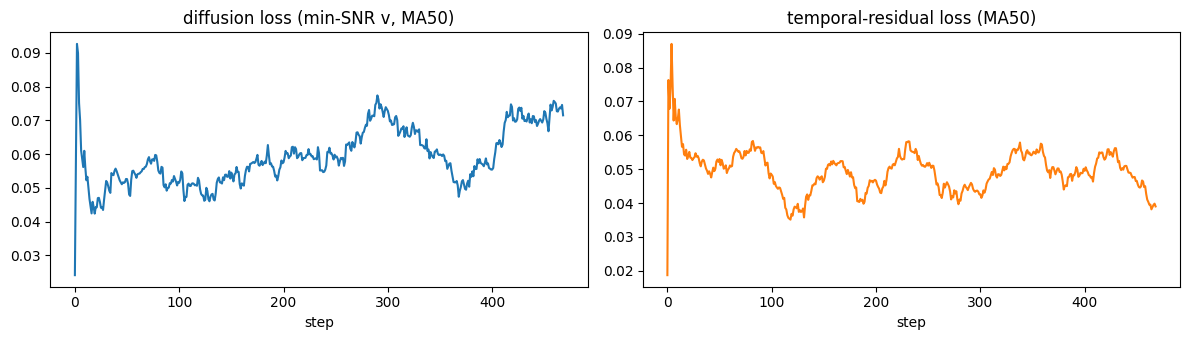

trained adapters active: /kaggle/working/tvsr_ckpt/adapters.pt (143 MB)


In [17]:
from pathlib import Path
from tvsr.train import download_davis, train
davis = None
if TRAIN or RUN_BENCHMARK or RUN_SHARP_SWEEP:
    try:
        davis = download_davis("/tmp/tvsr_data")
        print("DAVIS at", davis)
    except Exception as e:
        print("DAVIS download failed -> training and benchmark skipped:", repr(e)[:300])

if TRAIN and davis is not None and not (SKIP_TRAIN_IF_EXISTS and Path(ADAPTERS).exists()):
    hist = train(davis, out=ADAPTERS, minutes=TRAIN_MINUTES, workers=TRAIN_WORKERS)
    import matplotlib.pyplot as plt, pandas as pd
    h = pd.DataFrame(hist)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(h.step, h.l_diff.rolling(50, min_periods=1).mean()); ax[0].set_title("diffusion loss (min-SNR v, MA50)")
    ax[1].plot(h.step, h.l_temp.rolling(50, min_periods=1).mean(), c="C1"); ax[1].set_title("temporal-residual loss (MA50)")
    for a in ax: a.set_xlabel("step")
    plt.tight_layout(); plt.savefig(f"{RESULTS}/train_loss.png", dpi=120); plt.show()
    h.to_csv(f"{RESULTS}/train_history.csv", index=False)

if Path(ADAPTERS).exists():
    engine.use_adapters(ADAPTERS)
    print("trained adapters active:", ADAPTERS, f"({Path(ADAPTERS).stat().st_size / 2**20:.0f} MB)")
else:
    print("no adapters -> 'Ours' runs with the frozen prior (temporal layers are identity)")

## 6 · Quantitative report (unseen DAVIS-2017 val clips, known HR reference)
Protocol, as the reviewer asked: the annotated object is the target (box from its frame-0 mask). The clip is degraded ×4 with a fixed realistic degradation (blur σ 0.8, area down, noise σ 3, JPEG 75). Every method restores the **same tracked tube**, and metrics are computed **inside the object mask**.
* **Detail:** LPIPS ↓, HFEN ↓, sharpness ratio (1.0 = as sharp as the reference).
* **Flicker:** tLPIPS ↓, warp error ↓, computed with flow from the *reference*. The GT row shows the warp error of real motion.
* PSNR/SSIM are listed for completeness. They always favour smooth outputs (bicubic), so do not judge detail by them.
* Variants A–E (temporal-consistency mechanisms) run on identical tubes. ★ marks the one selected by the fixed rule: lowest LPIPS among variants with tLPIPS ≤ 0.04. That choice is saved and used by the interface. A frozen-prior row measures what training contributes.

In [18]:
import pandas as pd
from tvsr import benchmark
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
if RUN_BENCHMARK and davis is not None:
    items = benchmark.davis_val_items(davis, BENCH_SEQS, BENCH_FRAMES)
    print("sequences:", [it["name"] for it in items])
    t0 = time.time()
    df, agg, per_frame, best = benchmark.run(engine, items, RESULTS, preset=BENCH_PRESET,
                                             save_best=f"{WORK}/tvsr_ckpt/best_config.json")
    print(f"benchmark done in {(time.time() - t0) / 60:.1f} min")
    show = agg.rename(columns={"psnr": "PSNR-Y↑", "ssim": "SSIM↑", "lpips": "LPIPS↓", "hfen": "HFEN↓",
                               "sharp": "Sharp(1=ref)", "tlpips": "tLPIPS↓", "warp": "Warp×1e3↓",
                               "time_s": "time(s)", "tracker_iou": "track IoU"})
    display(show.round(4))

    # per-frame LPIPS (first sequence): detail over time
    import matplotlib.pyplot as plt
    plt.figure(figsize=(10, 3.5))
    for k, v in per_frame.items():
        if v and v[0]: plt.plot(v[0], label=k)
    plt.xlabel("frame"); plt.ylabel("LPIPS in object ↓"); plt.title(f"per-frame LPIPS · {items[0]['name']}")
    plt.legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{RESULTS}/per_frame_lpips.png", dpi=120); plt.show()

    def to_md(d):
        cols = list(d.columns)
        lines = ["| method | " + " | ".join(cols) + " |", "|---" * (len(cols) + 1) + "|"]
        for idx, r in d.iterrows():
            lines.append(f"| {idx} | " + " | ".join("–" if pd.isna(x) else f"{x:.4f}" for x in r.values) + " |")
        return "\n".join(lines)
    report = (f"# Benchmark: DAVIS-2017 val, {len(items)} clips x {BENCH_FRAMES} frames, x4, realistic degradation\n\n"
              f"Sequences: {', '.join(it['name'] for it in items)}  \nPreset: {BENCH_PRESET}  \n"
              f"Trained adapters: {engine.trained}  \nSelected (★): {best}\n\n" + to_md(show.round(4)) + "\n")
    Path(f"{RESULTS}/report.md").write_text(report)
    display(Markdown(report))
    for it in items:
        display(Markdown(f"**{it['name']}**: rows = methods, columns = 4 consecutive frames (zoomed target). "
                         f"All variants: `results/strip_all_{it['name']}.png`"))
        display(IImage(f"{RESULTS}/strip_{it['name']}.png", width=900))
else:
    print("benchmark skipped")

benchmark skipped


## 6b · Sharpness sweep (v4.2)
Same protocol and the same selection rule (★ = lowest LPIPS among variants with tLPIPS ≤ 0.04). Look at the **Sharp** column too: 1.0 means as sharp as the real video. The winner is saved to `best_config.json` and becomes the interface default. Every setting stays adjustable under *Sharpness* in the interface.

In [ ]:
from tvsr import benchmark
import pandas as pd
if RUN_SHARP_SWEEP and davis is not None:
    items = benchmark.davis_val_items(davis, SWEEP_SEQS, BENCH_FRAMES)
    print("sequences:", [it["name"] for it in items])
    t0 = time.time()
    sdf, sagg, _, sbest = benchmark.run(engine, items, f"{RESULTS}/sharpness_sweep", preset=BENCH_PRESET,
                                        variants=benchmark.SHARP_VARIANTS, baselines=False,
                                        frozen_ablation=False, save_best=f"{WORK}/tvsr_ckpt/best_config.json")
    print(f"sweep done in {(time.time() - t0) / 60:.1f} min · selected: {sbest}")
    print("settings now used by the interface:", engine.best_cfg)
    display(sagg.rename(columns={"psnr": "PSNR-Y↑", "ssim": "SSIM↑", "lpips": "LPIPS↓", "hfen": "HFEN↓",
                                 "sharp": "Sharp(1=ref)", "tlpips": "tLPIPS↓", "warp": "Warp×1e3↓",
                                 "time_s": "time(s)", "tracker_iou": "track IoU"}).round(4))
    for it in items:
        display(Markdown(f"**{it['name']}**: input · bicubic · GAN · ours ★ · ground truth"))
        display(IImage(f"{RESULTS}/sharpness_sweep/strip_{it['name']}.png", width=900))
    print("every variant side by side: results/sharpness_sweep/strip_all_<clip>.png")
else:
    print("sharpness sweep skipped")

sequences: ['car-roundabout', 'dog', 'horsejump-high', 'kite-surf']
== car-roundabout: box (250, 177, 440, 181), 24 frames
   D (v4.1 selection)                               LPIPS 0.2277  sharp 0.50  tLPIPS 0.0312  warp 3.64  (31s)
   D, colour anchor σ8                              LPIPS 0.2226  sharp 0.51  tLPIPS 0.0305  warp 3.95  (35s)
   D, anchor σ8 + detail restore 50%                LPIPS 0.2226  sharp 0.53  tLPIPS 0.0314  warp 4.03  (35s)
   D, anchor σ8 + detail restore 100%               LPIPS 0.2222  sharp 0.55  tLPIPS 0.0320  warp 4.13  (35s)
   D, anchor σ3 + detail restore 100%               LPIPS 0.2274  sharp 0.55  tLPIPS 0.0330  warp 3.84  (35s)
   D + second diffusion pass 0.3, σ8                LPIPS 0.2350  sharp 0.84  tLPIPS 0.0417  warp 6.72  (56s)
   D, Best preset (30 steps, 0.6, CFG 3)            LPIPS 0.2351  sharp 0.47  tLPIPS 0.0313  warp 3.68  (60s)
   D, Best preset, σ8 + detail restore 50%          LPIPS 0.2300  sharp 0.51  tLPIPS 0.0305  warp 4.07  (64

## 7 · (Optional) Run on your own video without the UI
Add your clip with **Add Input**, or upload it to `/kaggle/working`. Set `VIDEO` and the target `BOX = (x, y, w, h)` in the video's pixels on the frame at `START` seconds. Use the gridded preview printed below to read off the coordinates.

In [ ]:
VIDEO = ""                 # e.g. "/kaggle/input/my-clip/clip.mp4"
START, N_FRAMES = 0.0, 48
BOX = (0, 0, 0, 0)         # x, y, w, h on the frame at START
MODE = "enhance"           # "enhance" = real zoom-in | "evaluate" = treat upload as ground truth (x4 degraded)
PRESET = "Balanced"        # "Fast" | "Balanced" | "Best"

if VIDEO:
    import app
    from tvsr.video_io import probe, read_frame
    info = probe(VIDEO)
    f0 = read_frame(VIDEO, int(START * info["fps"]))
    grid = app.grid_overlay(f0, BOX if BOX[2] else None)
    cv2.imwrite(f"{WORK}/selection_grid.png", cv2.cvtColor(grid, cv2.COLOR_RGB2BGR))
    display(IImage(f"{WORK}/selection_grid.png", width=900))
    if BOX[2] > 0 and BOX[3] > 0:
        res = P.run_video(engine, VIDEO, BOX, START, N_FRAMES, mode=MODE, preset=PRESET,
                          image_diffusion=False, out_dir=f"{WORK}/my_run")
        print(res["msg"])
        display(pd.DataFrame(res["table"], columns=res["header"]))
        display(Video(res["tracked"], embed=True, width=900))
        display(Video(res["compare"], embed=True, width=900))
        print("files in", res["out_dir"])
    else:
        print("read the coordinates off the grid above, set BOX and re-run this cell")
else:
    print("skipped (set VIDEO)")

## 8 · Package the deliverables
This writes `tvsr_submission.zip` to `/kaggle/working`. It contains the code, README, trained adapters, benchmark tables, strips and the loss curve.

In [ ]:
import shutil
stage = f"{WORK}/submission"
shutil.rmtree(stage, ignore_errors=True)
shutil.copytree(PROJ, f"{stage}/code", ignore=shutil.ignore_patterns("__pycache__"))
if Path(ADAPTERS).exists(): shutil.copytree(Path(ADAPTERS).parent, f"{stage}/tvsr_ckpt")
if Path(RESULTS).exists(): shutil.copytree(RESULTS, f"{stage}/results", ignore=shutil.ignore_patterns("*.mp4"))
print(shutil.make_archive(f"{WORK}/tvsr_submission", "zip", stage))

## 9 · Launch the interface
A public `https://…gradio.live` link is printed. It works while this cell runs.
1. Upload a clip. The first frame appears with a **pixel-coordinate grid**.
2. Optional: move **Start time** to pick the selection frame.
3. **Click two opposite corners** of the target, or type x, y, w, h and press Enter. The selected pixels are previewed.
4. **Restore.** By default the **whole video from the start time** is processed with its original timing and **audio**. The red box follows the marked target through the clip. Choose the output layout:
   * **Inset:** your video with the moving box, plus a magnified enhanced view in the corner farthest from the target.
   * **In place:** the video upscaled, with the area around the box replaced by the enhanced pixels.
   * **Side by side:** video | enhanced zoom.

   You also get the synchronised method comparison, metrics on the target, a 4-frame strip, and the per-frame box coordinates (CSV). Time grows with clip length: roughly 1–2 min per 48 frames on *Balanced*. Untick *Whole video* to process a short piece.

Use **Evaluate** mode with an HD clip to get full-reference metrics. Use **Enhance** mode for a real zoom into any clip.

In [ ]:
import app
app.ENGINE = engine            # reuse the loaded (and trained) models
app.build_ui().queue().launch(share=True, debug=True)